# SEA-AD Multiregion taxonomy and snRNASeq analysis: clustering and annotations

Alzheimer's disease (AD) is characterized by the progressive accumulation of amyloid-beta (Aβ) plaques and hyperphosphorylated tau (pTau) tangles across brain regions. While these regions differ in architecture, function, and susceptibility to pathology, many share common cellular populations. The SEA-AD Multiregion Taxonomy was developed to provide a unified cellular framework for studying cellular vulnerability and molecular change across the full arc of canonical AD progression.

This taxonomy is derived from a multimodal dataset generated from 84 deeply characterized donors spanning the full spectrum of AD pathology. The dataset presented here contains approximately 6 million high-quality nuclei from single-nucleus RNA-seq and Multiome profiling, along with an additional 2.6 million nuclei that did not pass quality-control criteria. These data were generated alongside approximately 1 million single-nucleus ATAC-seq profiles, which informed multimodal analyses but are not included in the resources described here. Single-nucleus profiling was performed across ten brain regions: medial entorhinal cortex (MEC), lateral entorhinal cortex (LEC), hippocampus (HIP), inferior temporal gyrus (ITG), middle temporal gyrus (MTG), superior temporal gyrus (STG), dorsolateral prefrontal cortex (BA9), frontal insula (FI), angular gyrus (AnG), and primary visual cortex (V1C). Nuclei were mapped to an expanded reference taxonomy comprising 207 cell types, organized into 28 subclasses and 3 major cellular classes, including both broadly shared and regionally specialized populations. Cell type names are harmonized between studies; for example, Sst 25 from Gabitto, Travaglini et al. (2024) and Sst 25 in this taxonomy refer to the same cell population.

To generate this taxonomy, nuclei were subjected to standardized quality control, integrated across regions and modalities, and hierarchically mapped using deep-learning approaches based on scVI and scANVI. The resulting taxonomy provides consistent cell-type nomenclature across SEA-AD resources while preserving region-specific cellular specializations found in allocortical and neocortical regions. Spatial transcriptomic datasets were additionally used to anatomically localize newly defined excitatory populations within the hippocampus and entorhinal cortex. 

The notebook presented here demonstrates how to access and visualize taxonomy annotations, cell type metadata, donor information, brain region annotations, and AD-associated cellular changes from the SEA-AD multiregional dataset. These examples focus on precomputed metadata accessible through the Allen Brain Cell Atlas Access package. Additional data, including links to raw sequencing, spatial transcriptomic, and neuropathology data, are available at [SEA-AD.org](https://brain-map.org/consortia/sea-ad). 

In [1]:
%matplotlib inline

import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from typing import Tuple, Optional

from abc_atlas_access.abc_atlas_cache.abc_project_cache import AbcProjectCache

We will interact with the data using the **AbcProjectCache**. This cache object downloads data requested by the user, tracks which files have already been downloaded to your local system, and serves the path to the requested data on disk. For metadata, the cache can also directly serve up a Pandas DataFrame. See the [``getting_started``](https://alleninstitute.github.io/abc_atlas_access/notebooks/getting_started.html) notebook for more details on using the cache including installing it if it has not already been.

**Change the download_base variable to where you would like to download the data in your system or a location where a cache is already available.**

In [ ]:
download_base = Path('../../data/abc_atlas/')
abc_cache = AbcProjectCache.from_cache_dir(
   download_base
)

abc_cache.current_manifest

/Users/chris.morrison/src/abc_atlas_access/src/abc_atlas_access/abc_atlas_cache/cloud_cache.py:665: UserWarning: The manifest version recorded as last used for this cache -- releases/20261031/manifest.json-- is not a valid manifest for this dataset. Loading latest version -- releases/20260711/manifest.json -- instead.
  warnings.warn(msg, UserWarning)
/Users/chris.morrison/src/abc_atlas_access/src/abc_atlas_access/abc_atlas_cache/cloud_cache.py:697: OutdatedManifestWarning: You are loading
releases/20260711/manifest.json
which is newer than the most recent manifest file you have previously been working with
releases/20261031/manifest.json
It is possible that some data files have changed between these two data releases, which will force you to re-download those data files (currently downloaded files will not be overwritten). To continue using releases/20261031/manifest.json, run
type.load_manifest('releases/20261031/manifest.json')
  warnings.warn(msg, OutdatedManifestWarning)


'releases/20261031/manifest.json'

## Data overview

Below we list the metadata and gene expression files for each of the directories that make up this dataset:
- SEA-AD-Multiregion-10X
- SEA-AD-Multiregion-taxonomy

In [3]:
print("SEA-AD-10X: gene expression data (h5ad)\n\t", abc_cache.list_expression_matrix_files(directory='SEA-AD-Multiregion-10X'))
print("SEA-AD-Multiregion-10X: metadata (csv)\n\t", abc_cache.list_metadata_files(directory='SEA-AD-Multiregion-10X'))

SEA-AD-10X: gene expression data (h5ad)
	 ['AnG-10X/log2', 'AnG-10X/raw', 'DFC-10X/log2', 'DFC-10X/raw', 'FI-10X/log2', 'FI-10X/raw', 'HIP-10X/log2', 'HIP-10X/raw', 'ITG-10X/log2', 'ITG-10X/raw', 'LEC-10X/log2', 'LEC-10X/raw', 'MEC-10X/log2', 'MEC-10X/raw', 'MTG-10X/log2', 'MTG-10X/raw', 'STG-10X/log2', 'STG-10X/raw', 'V1C-10X/log2', 'V1C-10X/raw']
SEA-AD-Multiregion-10X: metadata (csv)
	 ['cell_metadata', 'disease', 'donor', 'example_gene_expression', 'gene', 'library', 'value_sets']


We will also use metadata from the SEA-AD-Multiregion-taxonomy directory. Below is the list of available files:

In [4]:
print("SEA-AD-Multiregion-taxonomy: metadata (csv)\n\t", abc_cache.list_metadata_files(directory='SEA-AD-Multiregion-taxonomy'))

SEA-AD-Multiregion-taxonomy: metadata (csv)
	 ['cell_2d_embedding_coordinates', 'cell_to_cluster_membership', 'cluster', 'cluster_annotation_term', 'cluster_annotation_term_set', 'cluster_to_cluster_annotation_membership']


### Cell metadata

Essential cell metadata is stored as a CSV file that we load as a Pandas DataFrame. Each row represents one cell indexed by a *cell label*. The *cell label* is the concatenation of barcode and name of the sample. In this context, the sample is the *barcoded cell sample* that represents a single load into one port of the 10x Chromium. Note that cell barcodes are only unique within a single *barcoded cell sample* and that the same barcode can be reused `exp_component_name` is an alternative cell identifier that indexes some of the data hosted at [SEA-AD.org](https://brain-map.org/consortia/sea-ad).

Each cell is associated with a *library label*, *donor label*, *alignment_job_id*, *feature_matrix_label* and *dataset_label* identifying which data package this cell is part of. This metadata file will be combined with other metadata files that come with this package to add information associated with the donor, UMAP coordinates, taxonomy assignments, and more.

Below, we load the first of the metadata used in this tutorial. This represents the cell metadata for the aligned dataset.

The command we use below both downloads the data if it is not already available in the local cache and loads the data as a Pandas DataFrame. This pattern of loading metadata is repeated throughout the tutorials.

In [5]:
cell = abc_cache.get_metadata_dataframe(
    directory='SEA-AD-Multiregion-10X',
    file_name='cell_metadata'
).set_index('cell_label')
print("Number of cells = ", len(cell))
cell.head()

cell_metadata.csv: 100%|██████████| 1.64G/1.64G [01:31<00:00, 18.0MMB/s]   
/Users/chris.morrison/src/abc_atlas_access/src/abc_atlas_access/abc_atlas_cache/abc_project_cache.py:643: DtypeWarning: Columns (0: alignment_job_id) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path, **kwargs)


Number of cells =  8641342


,cell_barcode,barcoded_cell_sample_label,library_label,alignment_job_id,doublet_score,umi_count,donor_label,exp_component_name,feature_matrix_label,dataset_label
cell_label,,,,,,,,,,
AAACAGCCACTGGCTG-2001_A08,AAACAGCCACTGGCTG,2001_A08,L8XR_231221_02_D02,1322484698,0.184615,54020.0,H21.33.001,AAACAGCCACTGGCTG-L8XR_231221_02_D02-1322484698,AnG-10X,SEA-AD-Multiregion-10X
AAACAGCCAGGTTATT-2001_A08,AAACAGCCAGGTTATT,2001_A08,L8XR_231221_02_D02,1322484698,0.060606,4438.0,H21.33.001,AAACAGCCAGGTTATT-L8XR_231221_02_D02-1322484698,AnG-10X,SEA-AD-Multiregion-10X
AAACAGCCATTCCTCG-2001_A08,AAACAGCCATTCCTCG,2001_A08,L8XR_231221_02_D02,1322484698,0.276923,66285.0,H21.33.001,AAACAGCCATTCCTCG-L8XR_231221_02_D02-1322484698,AnG-10X,SEA-AD-Multiregion-10X
AAACATGCAATGCCTA-2001_A08,AAACATGCAATGCCTA,2001_A08,L8XR_231221_02_D02,1322484698,0.060606,6019.0,H21.33.001,AAACATGCAATGCCTA-L8XR_231221_02_D02-1322484698,AnG-10X,SEA-AD-Multiregion-10X
AAACATGCACCTCACC-2001_A08,AAACATGCACCTCACC,2001_A08,L8XR_231221_02_D02,1322484698,0.181818,48653.0,H21.33.001,AAACATGCACCTCACC-L8XR_231221_02_D02-1322484698,AnG-10X,SEA-AD-Multiregion-10X


We can use pandas `groupby` function to see how many unique items are associated for each field and list them out if the number of unique items is small.

In [6]:
def print_column_info(df):
    
    for c in df.columns:
        grouped = df[[c]].groupby(c).count()
        members = ''
        if len(grouped) < 30:
            members = str(list(grouped.index))
        print("Number of unique %s = %d %s" % (c, len(grouped), members))

In [7]:
print_column_info(cell)

Number of unique cell_barcode = 3767416 
Number of unique barcoded_cell_sample_label = 908 
Number of unique library_label = 908 
Number of unique alignment_job_id = 913 
Number of unique doublet_score = 2792 
Number of unique umi_count = 177044 
Number of unique donor_label = 84 
Number of unique exp_component_name = 8641342 
Number of unique feature_matrix_label = 10 ['AnG-10X', 'DFC-10X', 'FI-10X', 'HIP-10X', 'ITG-10X', 'LEC-10X', 'MEC-10X', 'MTG-10X', 'STG-10X', 'V1C-10X']
Number of unique dataset_label = 1 ['SEA-AD-Multiregion-10X']


### Donor, Library, and Disease metadata

The first two associated metadata we load are the `donor`, `library`, and `disease` tables. The donor table includes donor demographics such as species, age, sex, race, and education, along with brain tissue metrics such as pH, postmortem interval (PMI), and fresh brain weight. This table also indicates which study a donor was enrolled in (ACT or ADRC). The library table contains information on 10X methods and brain region of interest the tissue was extracted from. The disease table contains disease progression metrics and other pathology data. Definitions of many of these columns can be found [here](https://cdn.prod.website-files.com/689cfbd308fa7373b604d290/6a458356cbaf777f617ae687_sea-ad_donorindex_dataelementbriefdescriptions_063026.pdf).

In [8]:
donor = abc_cache.get_metadata_dataframe(
    directory='SEA-AD-Multiregion-10X',
    file_name='donor',
).set_index('donor_label')

donor

donor.csv: 100%|██████████| 17.1k/17.1k [00:00<00:00, 182kMB/s]


,donor_species,species_scientific_name,species_genus,donor_sex,donor_gender,donor_age,donor_age_value,donor_age_unit,Race (choice=White),Race (choice=Black/ African American),...,Race (choice=Other),Hispanic/Latino,specify other race,Highest level of education,Years of education,PMI,Fresh Brain Weight,Brain pH,Primary Study Name,donor_race
donor_label,,,,,,,,,,,,,,,,,,,,,
H19.33.004,NCBITaxon:9606,Homo sapiens,Human,Female,Female,80 yrs,80,years,Checked,Unchecked,...,Unchecked,No,NaN,Bachelors,17,8.133333,1035.0,7.0,ACT,White
H20.33.001,NCBITaxon:9606,Homo sapiens,Human,Male,Male,82 yrs,82,years,Checked,Unchecked,...,Unchecked,No,NaN,Bachelors,16,7.700000,1338.0,6.8,ACT,White
H20.33.002,NCBITaxon:9606,Homo sapiens,Human,Female,Female,97 yrs,97,years,Checked,Unchecked,...,Unchecked,No,NaN,High School,12,4.333333,1078.0,7.3,ACT,White
H20.33.004,NCBITaxon:9606,Homo sapiens,Human,Male,Male,86 yrs,86,years,Checked,Unchecked,...,Unchecked,No,NaN,Trade School/ Tech School,15,8.833333,1261.0,6.7,ACT,White
H20.33.005,NCBITaxon:9606,Homo sapiens,Human,Female,Female,99 yrs,99,years,Checked,Unchecked,...,Unchecked,No,NaN,High School,12,7.600000,1003.0,6.8,ACT,White
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
H21.33.043,NCBITaxon:9606,Homo sapiens,Human,Female,Female,95 yrs,95,years,Checked,Unchecked,...,Unchecked,No,NaN,Bachelors,16,4.400000,1082.0,6.6,ACT,White
H21.33.044,NCBITaxon:9606,Homo sapiens,Human,Female,Female,88 yrs,88,years,Checked,Unchecked,...,Unchecked,No,NaN,Trade School/ Tech School,15,7.000000,1168.0,6.6,ACT,White
H21.33.045,NCBITaxon:9606,Homo sapiens,Human,Female,Female,94 yrs,94,years,Unchecked,Unchecked,...,Unchecked,No,NaN,High School,12,4.000000,925.0,7.2,ADRC Clinical Core,Asian


Next we load the library metadata. The information we will primarily use from this table are the region of interest that each library is associated with

In [9]:
library = abc_cache.get_metadata_dataframe(
    directory='SEA-AD-Multiregion-10X',
    file_name='library'
).set_index('library_label')
library

library.csv: 100%|██████████| 117k/117k [00:00<00:00, 935kMB/s] 


,library_method,barcoded_cell_sample_label,enrichment_population,cell_specimen_type,region_of_interest_label,region_of_interest_name,parcellation_term_identifier,Brain Region,donor_label
library_label,,,,,,,,,
L8XR_231221_02_D02,10xMultiome;GEX,2001_A08,"70% NeuN+, 30% NeuN-",Nuclei,AnG,angular gyrus,DHBA:12136,AnG,H21.33.001
L8XR_231130_21_B02,10xMultiome;GEX,1963_A06,"70% NeuN+, 30% NeuN-",Nuclei,AnG,angular gyrus,DHBA:12136,AnG,H21.33.002
L8XR_231116_02_B08,10xMultiome;GEX,1957_A08,"70% NeuN+, 30% NeuN-",Nuclei,AnG,angular gyrus,DHBA:12136,AnG,H20.33.035
L8XR_231130_21_E02,10xMultiome;GEX,1967_B09,"70% NeuN+, 30% NeuN-",Nuclei,AnG,angular gyrus,DHBA:12136,AnG,H21.33.028
L8XR_231221_02_G02,10xMultiome;GEX,2001_C08,"70% NeuN+, 30% NeuN-",Nuclei,AnG,angular gyrus,DHBA:12136,AnG,H21.33.004
...,...,...,...,...,...,...,...,...,...
L8XR_240530_01_G08,10xMultiome;GEX,2252_A07,"70% NeuN+, 30% NeuN-",Nuclei,FI,frontal agranular insular cortex (area FI),DHBA:10329,FI,H20.33.018
L8XR_240607_02_A04,10xMultiome;GEX,2252_B07,"70% NeuN+, 30% NeuN-",Nuclei,FI,frontal agranular insular cortex (area FI),DHBA:10329,FI,H20.33.028
L8XR_240607_02_F04,10xMultiome;GEX,2252_C07,"70% NeuN+, 30% NeuN-",Nuclei,FI,frontal agranular insular cortex (area FI),DHBA:10329,FI,H20.33.033


Finally we load the disease data containing disease progression information.

In [10]:
disease = abc_cache.get_metadata_dataframe(
    directory='SEA-AD-Multiregion-10X',
    file_name='disease'
).set_index('donor_label')
disease

disease.csv: 100%|██████████| 14.4k/14.4k [00:00<00:00, 206kMB/s]


,Overall AD neuropathological Change,Thal,Braak,CERAD score,Overall CAA Score,Highest Lewy Body Disease,Total Microinfarcts (not observed grossly),Total microinfarcts in screening sections,Atherosclerosis,Arteriolosclerosis,...,Cognitive Status,Last CASI Score,Interval from last CASI in months,Last MMSE Score,Interval from last MMSE in months,Last MOCA Score,Interval from last MOCA in months,APOE Genotype,Severely Affected Donor,CPS_Global
donor_label,,,,,,,,,,,,,,,,,,,,,
H19.33.004,Not AD,Thal 0,Braak IV,Absent,Not identified,Not Identified (olfactory bulb not assessed),1,1,Mild,Moderate,...,No dementia,85.0,3.5,25.0,3.5,NaN,NaN,3/3,N,0.102055
H20.33.001,Low,Thal 2,Braak IV,Sparse,Not identified,Not Identified (olfactory bulb not assessed),0,0,Mild,Mild,...,No dementia,97.0,18.2,28.0,18.2,NaN,NaN,3/3,N,0.390107
H20.33.002,Not AD,Thal 0,Braak IV,Absent,Not identified,Limbic (Transitional),0,0,Moderate,Moderate,...,No dementia,93.0,46.1,33.0,22.6,NaN,NaN,2/3,N,0.081825
H20.33.004,High,Thal 5,Braak V,Frequent,Moderate,Neocortical (Diffuse),0,0,Mild,Severe,...,Dementia,80.0,55.7,25.0,55.7,NaN,NaN,3/4,N,0.754141
H20.33.005,Intermediate,Thal 3,Braak IV,Moderate,Moderate,Not Identified (olfactory bulb not assessed),2,2,Mild,Moderate,...,No dementia,94.0,24.2,29.0,24.2,NaN,NaN,2/3,N,0.276006
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
H21.33.043,Low,Thal 4,Braak II,Sparse,Not identified,Not Identified (olfactory bulb assessed),1,0,Moderate,Moderate,...,Dementia,97.0,35.1,29.0,35.1,NaN,NaN,3/3,N,0.580067
H21.33.044,Intermediate,Thal 3,Braak VI,Frequent,Moderate,Not Identified (olfactory bulb not assessed),9,9,Mild,Severe,...,Dementia,81.0,8.9,21.0,8.9,NaN,NaN,3/3,N,0.731159
H21.33.045,High,Thal 4,Braak VI,Frequent,Moderate,Limbic (Transitional),0,0,Moderate,Moderate,...,Dementia,NaN,NaN,17.0,65.3,NaN,NaN,3/4,Y,0.962116


We combine the donor, library, and disease tables into an extended cell metadata table.

In [11]:
cell_extended = cell.join(donor, on='donor_label')
cell_extended = cell_extended.join(library, on='library_label', rsuffix='_library_table')
cell_extended = cell_extended.join(disease, on='donor_label', rsuffix='_disease')

del cell

We use the `groupby` function to show the number of cells for one of disease data columns. Change this to any other column to get counts by any of the various metadata.

In [12]:
cell_extended.groupby('region_of_interest_name')[['region_of_interest_label']].count()

,region_of_interest_label
region_of_interest_name,
angular gyrus,389804
dorsolateral prefrontal cortex,1807513
frontal agranular insular cortex (area FI),321843
hippocampus (hippocampal formation),307789
inferior temporal gyrus,626792
lateral (anterior) entorhinal cortex,239721
medial (posterior) entorhinal cortex,1485051
middle temporal gyrus,1861334
"primary visual cortex (striate cortex, area V1/17)",867151


We can use the group by functionality to group the cells by cognitive status.

In [13]:
cell_extended.groupby('Cognitive Status')[['library_label']].count().rename(columns={'library_label': 'number_of_cells'})

,number_of_cells
Cognitive Status,
Dementia,3943893
No dementia,4697449


### Adding color and feature order

Each major feature in the donor and library table is associated with unique colors and an ordering with the set of values. Below we load the `value_sets` DataFrame which is a mapping from the various value in the donor and species tables to those colors and orderings. We incorporate these values into the cell metadata table. 

In [14]:
value_sets = abc_cache.get_metadata_dataframe(
    directory='SEA-AD-Multiregion-10X',
    file_name='value_sets'
).set_index('label')
value_sets

value_sets.csv: 100%|██████████| 15.6k/15.6k [00:00<00:00, 199kMB/s]


,field,table,color_hex_triplet,order,description,external_identifier
label,,,,,,
2/2,APOE Genotype,disease,#fdd4c2,1,NaN,NaN
2/3,APOE Genotype,disease,#fca082,2,NaN,NaN
2/4,APOE Genotype,disease,#fb6a4a,3,NaN,NaN
3/3,APOE Genotype,disease,#e32f27,4,NaN,NaN
3/4,APOE Genotype,disease,#b21218,5,NaN,NaN
...,...,...,...,...,...,...
FI,region_of_interest_label,library,#008080,7,agranular frontal insular cortex (area FI),DHBA:10329
STG,region_of_interest_label,library,#006400,8,superior temporal gyrus,DHBA:12140
DFC,region_of_interest_label,library,#00008b,9,dorsolateral prefrontal cortex,DHBA:10173


We define a convenience function to add colors for the various values in the data (e.g. unique region of interest or donor sex values).

In [15]:
def extract_value_set(
        cell_metadata_df: pd.DataFrame,
        input_value_set: pd.DataFrame,
        input_value_set_label: str,
        dataframe_column: Optional[str] = None
    ):
    """Add color and order columns to the cell metadata dataframe based on the input
    value set.

    Columns are added as {input_value_set_label}_color and {input_value_set_label}_order.

    Parameters
    ----------
    cell_metadata_df : pd.DataFrame
        DataFrame containing cell metadata.
    input_value_set : pd.DataFrame
        DataFrame containing the value set information.
    input_value_set_label : str
        The the column name to extract color and order information for. will be added to the cell metadata.
    """
    if dataframe_column is None:
        dataframe_column = input_value_set_label
    cell_metadata_df[f'{dataframe_column}_color'] = input_value_set[
        input_value_set['field'] == input_value_set_label
    ].loc[cell_metadata_df[dataframe_column]]['color_hex_triplet'].values
    cell_metadata_df[f'{dataframe_column}_order'] = input_value_set[
        input_value_set['field'] == input_value_set_label
    ].loc[cell_metadata_df[dataframe_column]]['order'].values

Use our function to add the relevant color and order columns to our cell_metadata table.

In [16]:
# Add region of interest color and order
extract_value_set(cell_extended, value_sets, 'region_of_interest_label')
# Add disease color and order
extract_value_set(cell_extended, value_sets, 'APOE Genotype')
extract_value_set(cell_extended, value_sets, 'Arteriolosclerosis')
extract_value_set(cell_extended, value_sets, 'Atherosclerosis')
extract_value_set(cell_extended, value_sets, 'Braak')
extract_value_set(cell_extended, value_sets, 'CERAD score')
extract_value_set(cell_extended, value_sets, 'Cognitive Status')
extract_value_set(cell_extended, value_sets, 'LATE')
extract_value_set(cell_extended, value_sets, 'Highest Lewy Body Disease')
extract_value_set(cell_extended, value_sets, 'Overall AD neuropathological Change')
extract_value_set(cell_extended, value_sets, 'Severely Affected Donor')
extract_value_set(cell_extended, value_sets, 'Thal')
# Add donor sex/gender color and order
extract_value_set(cell_extended, value_sets, 'donor_sex')
extract_value_set(cell_extended, value_sets, 'donor_gender')
# Add race
extract_value_set(cell_extended, value_sets, 'donor_race')
cell_extended.head()

,cell_barcode,barcoded_cell_sample_label,library_label,alignment_job_id,doublet_score,umi_count,donor_label,exp_component_name,feature_matrix_label,dataset_label,...,Severely Affected Donor_color,Severely Affected Donor_order,Thal_color,Thal_order,donor_sex_color,donor_sex_order,donor_gender_color,donor_gender_order,donor_race_color,donor_race_order
cell_label,,,,,,,,,,,,,,,,,,,,,
AAACAGCCACTGGCTG-2001_A08,AAACAGCCACTGGCTG,2001_A08,L8XR_231221_02_D02,1322484698,0.184615,54020.0,H21.33.001,AAACAGCCACTGGCTG-L8XR_231221_02_D02-1322484698,AnG-10X,SEA-AD-Multiregion-10X,...,#fb6a4a,1,#fc8161,3,#ADC4C3,2,#ADC4C3,2,#f7f184,125
AAACAGCCAGGTTATT-2001_A08,AAACAGCCAGGTTATT,2001_A08,L8XR_231221_02_D02,1322484698,0.060606,4438.0,H21.33.001,AAACAGCCAGGTTATT-L8XR_231221_02_D02-1322484698,AnG-10X,SEA-AD-Multiregion-10X,...,#fb6a4a,1,#fc8161,3,#ADC4C3,2,#ADC4C3,2,#f7f184,125
AAACAGCCATTCCTCG-2001_A08,AAACAGCCATTCCTCG,2001_A08,L8XR_231221_02_D02,1322484698,0.276923,66285.0,H21.33.001,AAACAGCCATTCCTCG-L8XR_231221_02_D02-1322484698,AnG-10X,SEA-AD-Multiregion-10X,...,#fb6a4a,1,#fc8161,3,#ADC4C3,2,#ADC4C3,2,#f7f184,125
AAACATGCAATGCCTA-2001_A08,AAACATGCAATGCCTA,2001_A08,L8XR_231221_02_D02,1322484698,0.060606,6019.0,H21.33.001,AAACATGCAATGCCTA-L8XR_231221_02_D02-1322484698,AnG-10X,SEA-AD-Multiregion-10X,...,#fb6a4a,1,#fc8161,3,#ADC4C3,2,#ADC4C3,2,#f7f184,125
AAACATGCACCTCACC-2001_A08,AAACATGCACCTCACC,2001_A08,L8XR_231221_02_D02,1322484698,0.181818,48653.0,H21.33.001,AAACATGCACCTCACC-L8XR_231221_02_D02-1322484698,AnG-10X,SEA-AD-Multiregion-10X,...,#fb6a4a,1,#fc8161,3,#ADC4C3,2,#ADC4C3,2,#f7f184,125


### UMAP spatial embedding

Now that we've merged our donor and library metadata into the main cells data, our next step is to plot these values in the Uniform Manifold Approximation and Projection (UMAP) for cells in the dataset. The UMAP is a dimension reduction technique that can be used for visualizing and exploring large-dimension datasets. 

Below we load this 2-D embedding for a sub selection of our cells and merge the x-y coordinates into the extended cell metadata we are creating. 

In [17]:
cell_2d_embedding_coordinates = abc_cache.get_metadata_dataframe(
    directory='SEA-AD-Multiregion-taxonomy',
    file_name='cell_2d_embedding_coordinates'
).set_index('cell_label')
cell_2d_embedding_coordinates.head()

cell_2d_embedding_coordinates.csv: 100%|██████████| 273M/273M [00:17<00:00, 15.2MMB/s]   


,x,y
cell_label,,
AAACAGCCACTGGCTG-2001_A08,7.009472,14.111731
AAACAGCCAGGTTATT-2001_A08,-1.319671,-1.221017
AAACAGCCATTCCTCG-2001_A08,17.003418,10.816355
AAACATGCAATGCCTA-2001_A08,17.077744,2.317490
AAACATGCACCTCACC-2001_A08,19.195032,1.132652


After joining the UMAPS coordinates into our full cell metadata table, we'll subset every 10th cell the full dataset for ease of plotting.

In [18]:
cell_extended = cell_extended.join(cell_2d_embedding_coordinates, how='inner')
cell_extended = cell_extended.sample(frac=1) # shuffle the rows for plotting purposes
plot_cell_extended = cell_extended[::10]

del cell_2d_embedding_coordinates

We define a small helper function *plot_umap* to visualize the cells on the UMAP. In the examples below we will plot associated cell information colorized by donor age, sex, region of interest,etc.

In [19]:
def plot_umap(
    xx: np.ndarray,
    yy: np.ndarray,
    cc: np.ndarray = None,
    val: np.ndarray = None,
    fig_width: float = 8,
    fig_height: float = 8,
    cmap: Optional[plt.Colormap] = None,
    labels: np.ndarray = None,
    term_orders: np.ndarray = None,
    colorbar: bool = False,
    sizes: np.ndarray = None,
    limit_plot: bool = True,
    fig: plt.Figure = None,
    ax: plt.Axes = None,
 ) -> Tuple[plt.Figure, plt.Axes]:
    """
    Plot a scatter plot of the UMAP coordinates.

    Parameters
    ----------
    xx : array-like
        x-coordinates of the points to plot.
    yy : array-like
        y-coordinates of the points to plot.
    cc : array-like, optional
        colors of the points to plot. If None, the points will be colored by the values in `val`.
    val : array-like, optional
        values of the points to plot. If None, the points will be colored by the values in `cc`.
    fig_width : float, optional
        width of the figure in inches. Default is 8.
    fig_height : float, optional
        height of the figure in inches. Default is 8.
    cmap : str, optional
        colormap to use for coloring the points. If None, the points will be colored by the values in `cc`.
    labels : array-like, optional
        labels for the points to plot. If None, no labels will be added to the plot.
    term_orders : array-like, optional
        order of the labels for the legend. If None, the labels will be ordered by their appearance in `labels`.
    colorbar : bool, optional
        whether to add a colorbar to the plot. Default is False.
    sizes : array-like, optional
        sizes of the points to plot. If None, all points will have the same size.
    """
    if sizes is None:
        sizes = 1
    if fig is None or ax is None:
        fig, ax = plt.subplots()
        fig.set_size_inches(fig_width, fig_height)

    if cmap is not None:
        scatt = ax.scatter(xx, yy, c=val, s=0.5, marker='.', cmap=cmap, alpha=sizes)
    elif cc is not None:
        scatt = ax.scatter(xx, yy, c=cc, s=0.5, marker='.', alpha=sizes)

    if labels is not None:
        from matplotlib.patches import Rectangle
        unique_label_colors = (labels + ',' + cc).unique()
        unique_labels = np.array([label_color.split(',')[0] for label_color in unique_label_colors])
        unique_colors = np.array([label_color.split(',')[1] for label_color in unique_label_colors])

        if term_orders is not None:
            unique_order = term_orders.unique()
            term_order = np.argsort(unique_order)
            unique_labels = unique_labels[term_order]
            unique_colors = unique_colors[term_order]
            
        rects = []
        for color in unique_colors:
            rects.append(Rectangle((0, 0), 1, 1, fc=color))

        legend = ax.legend(rects, unique_labels, loc=1)
        # ax.add_artist(legend)

    if colorbar:
        fig.colorbar(scatt, ax=ax)
    
    return fig, ax

Plot the various donor and library metadata available.

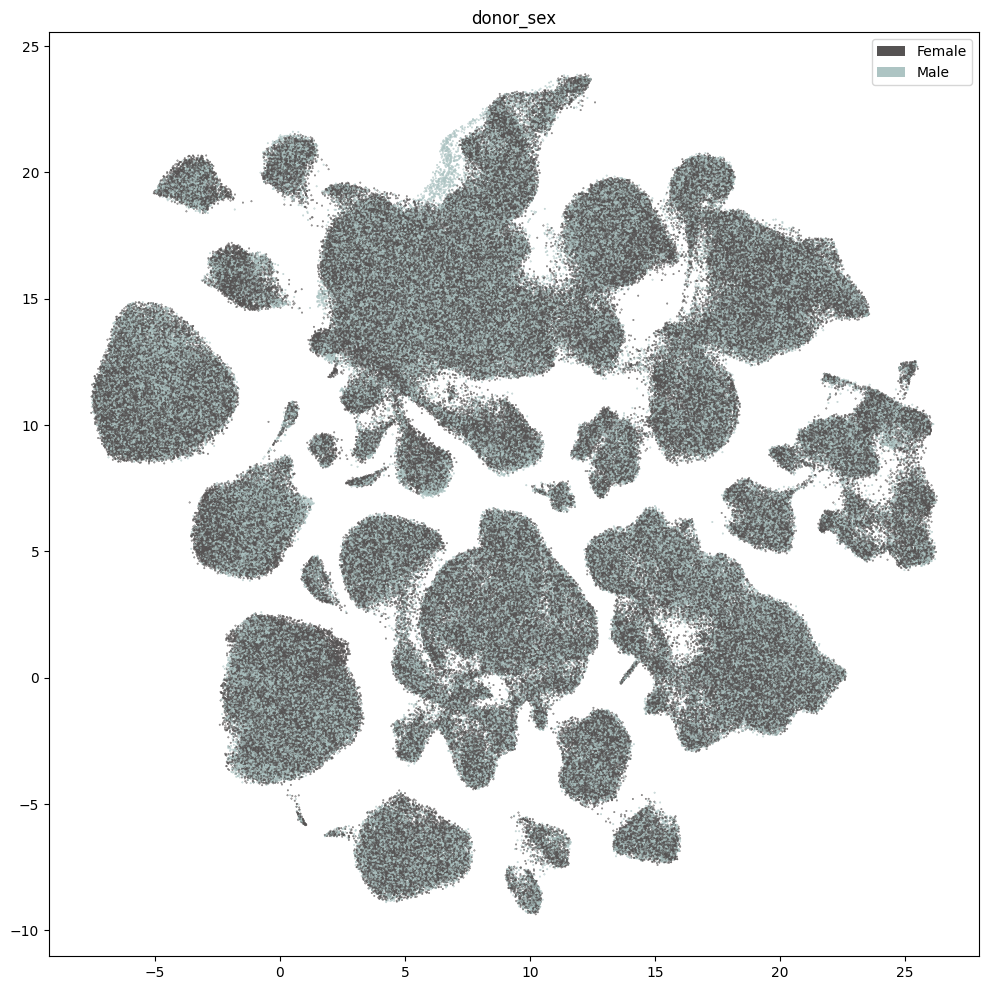

In [20]:
fig, ax = plot_umap(
    plot_cell_extended['x'],
    plot_cell_extended['y'],
    cc=plot_cell_extended['donor_sex_color'],
    labels=plot_cell_extended['donor_sex'],
    term_orders=plot_cell_extended['donor_sex_order'],
    fig_width=12,
    fig_height=12
)
res = ax.set_title("donor_sex")
plt.show()

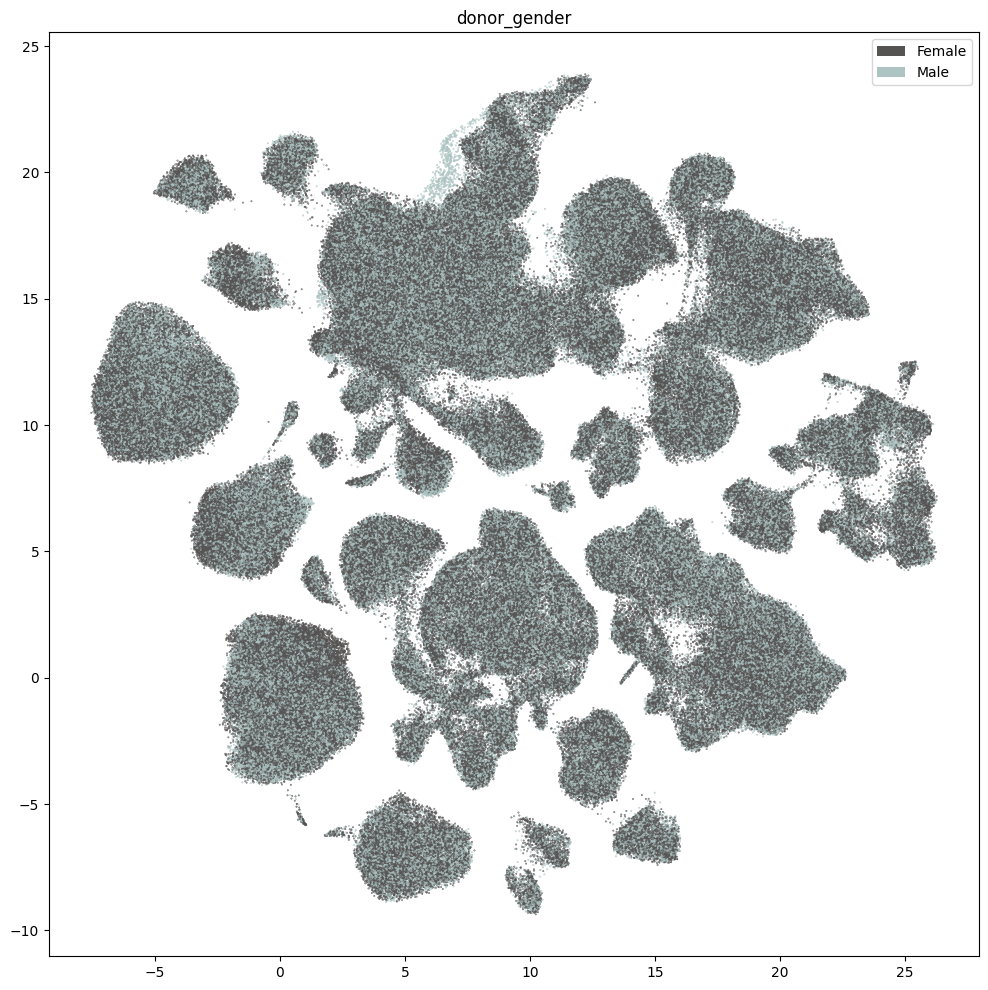

In [21]:
fig, ax = plot_umap(
    plot_cell_extended['x'],
    plot_cell_extended['y'],
    cc=plot_cell_extended['donor_gender_color'],
    labels=plot_cell_extended['donor_gender'],
    term_orders=plot_cell_extended['donor_gender_order'],
    fig_width=12,
    fig_height=12
)
res = ax.set_title("donor_gender")
plt.show()

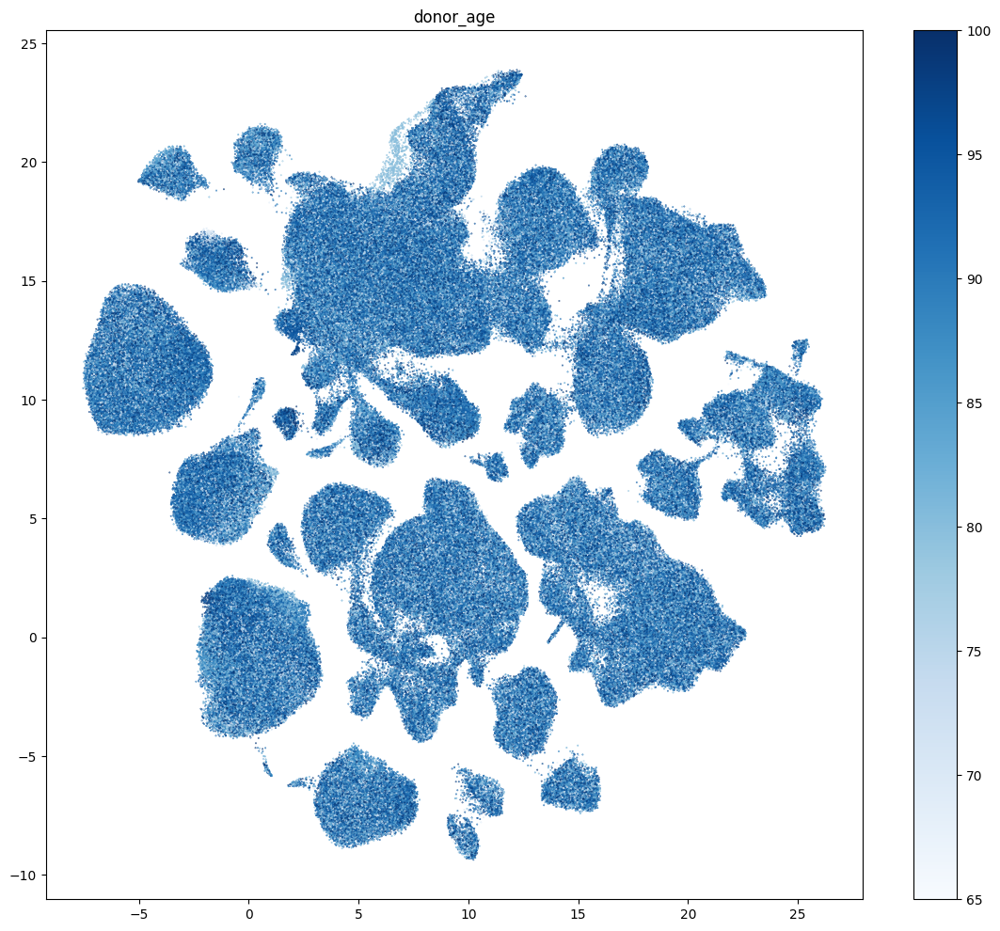

In [22]:
fig, ax = plot_umap(
    plot_cell_extended['x'],
    plot_cell_extended['y'],
    val=plot_cell_extended['donor_age_value'],
    cmap=plt.cm.Blues,
    fig_width=14,
    fig_height=12,
    colorbar=True,
)
res = ax.set_title("donor_age")
plt.show()

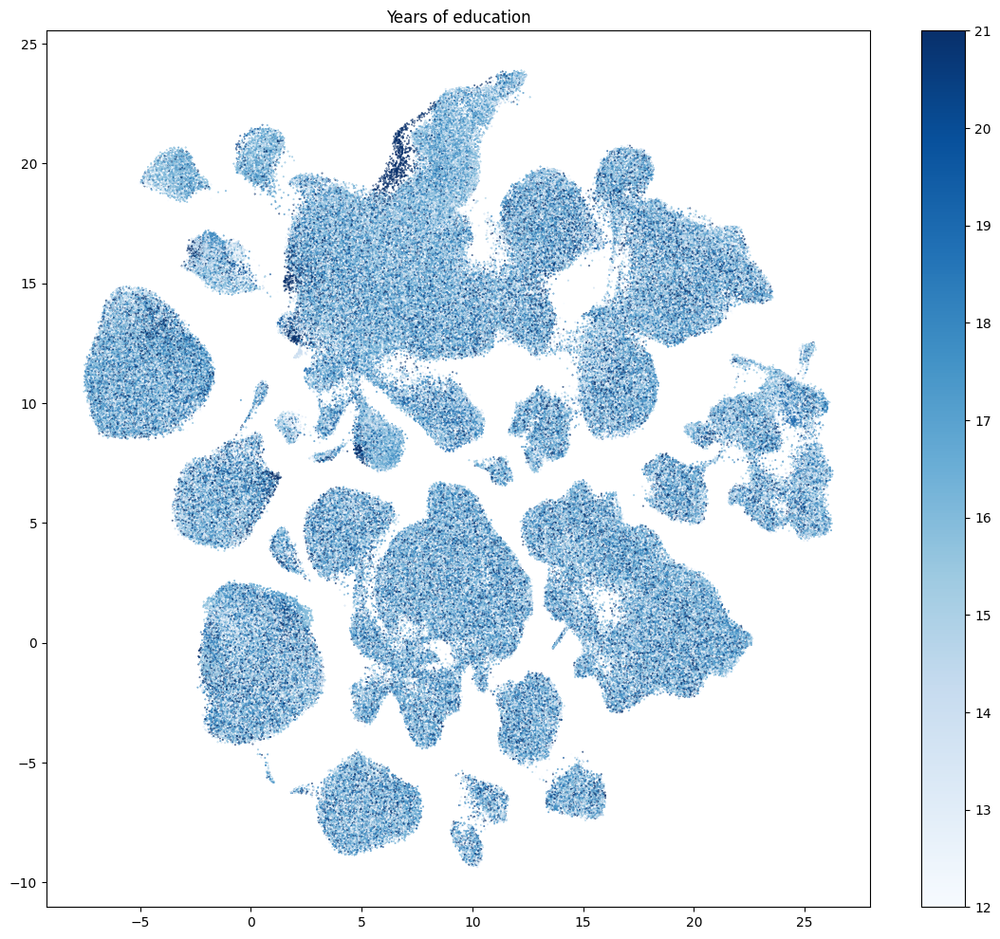

In [23]:
fig, ax = plot_umap(
    plot_cell_extended['x'],
    plot_cell_extended['y'],
    val=plot_cell_extended['Years of education'],
    cmap=plt.cm.Blues,
    fig_width=14,
    fig_height=12,
    colorbar=True,
)
res = ax.set_title("Years of education")
plt.show()

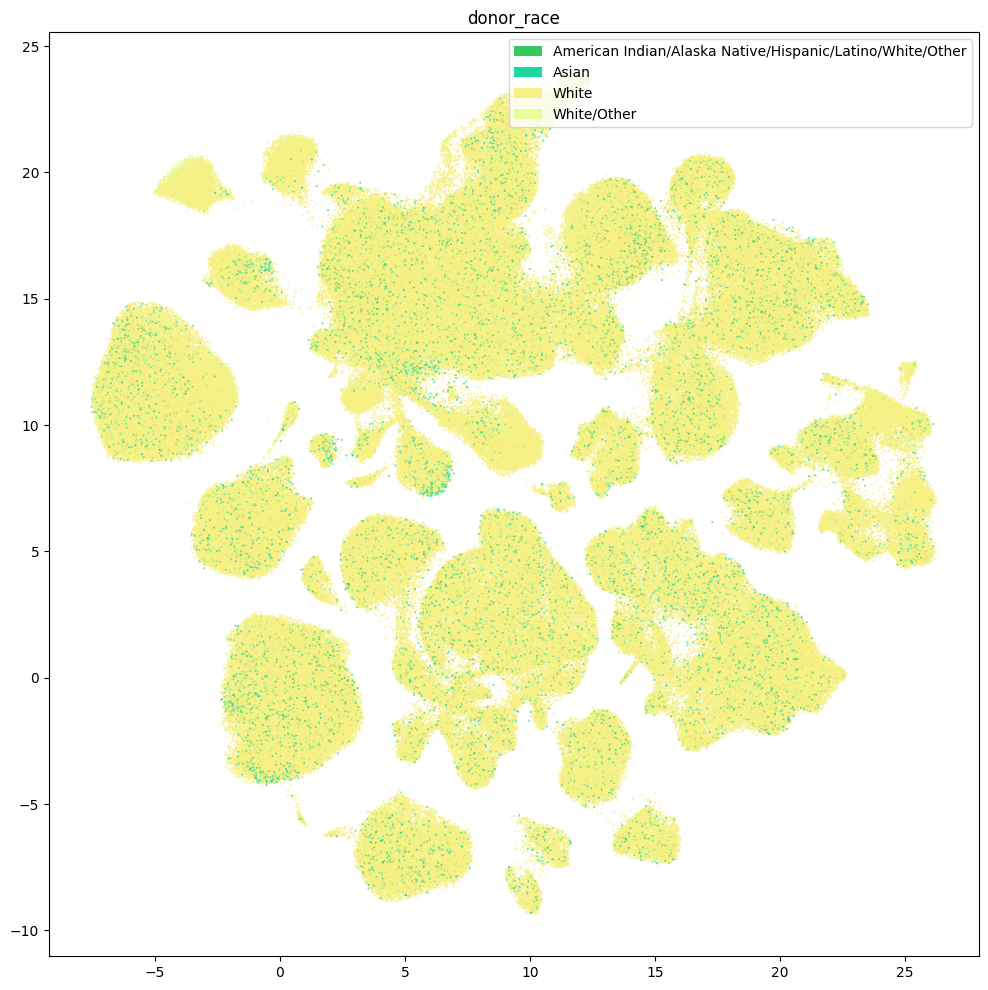

In [24]:
fig, ax = plot_umap(
    plot_cell_extended['x'],
    plot_cell_extended['y'],
    cc=plot_cell_extended['donor_race_color'],
    labels=plot_cell_extended['donor_race'],
    term_orders=plot_cell_extended['donor_race_order'],
    fig_width=12,
    fig_height=12
)
res = ax.set_title("donor_race")
plt.show()

Below we show the region of interest for the cells in the dataset.

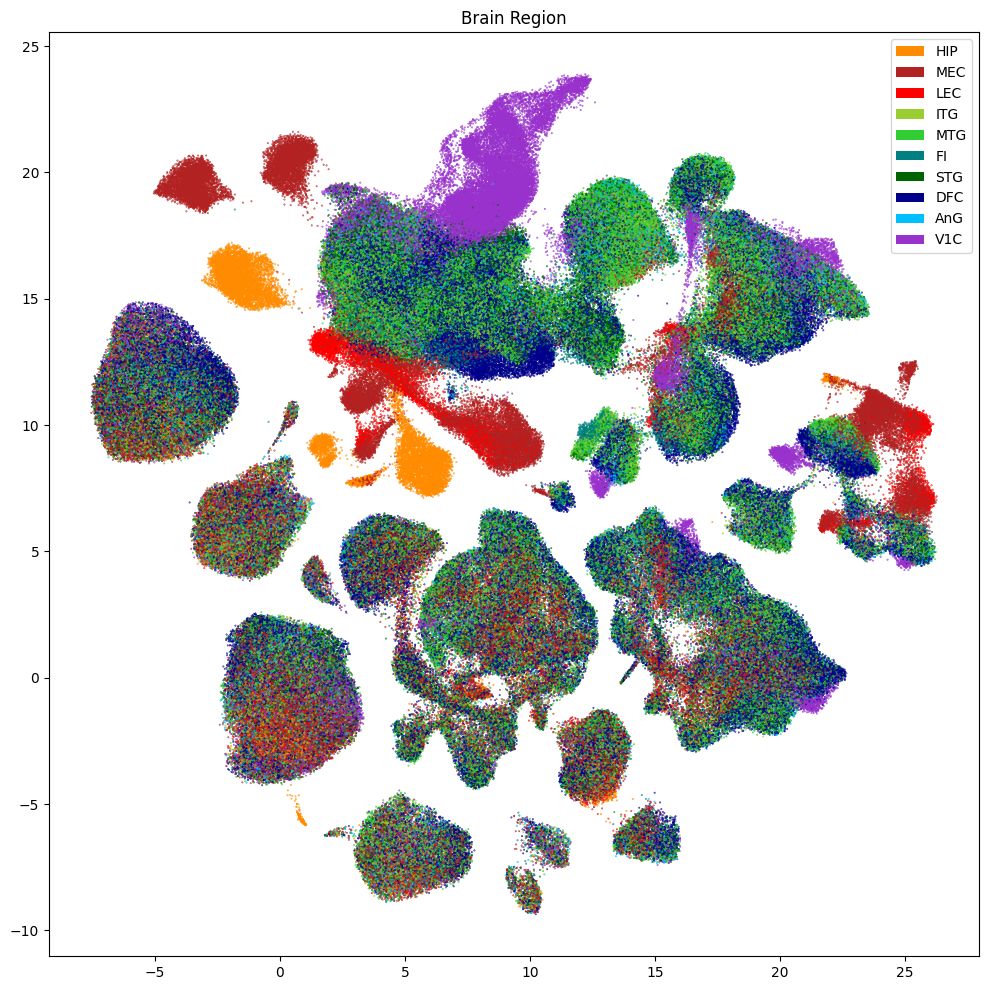

In [25]:
fig, ax = plot_umap(
    plot_cell_extended['x'],
    plot_cell_extended['y'],
    cc=plot_cell_extended['region_of_interest_label_color'],
    labels=plot_cell_extended['region_of_interest_label'],
    term_orders=plot_cell_extended['region_of_interest_label_order'],
    fig_width=12,
    fig_height=12
)
res = ax.set_title("Brain Region")
plt.show()

New we plot the UMAP with for the various disease markers in the data.

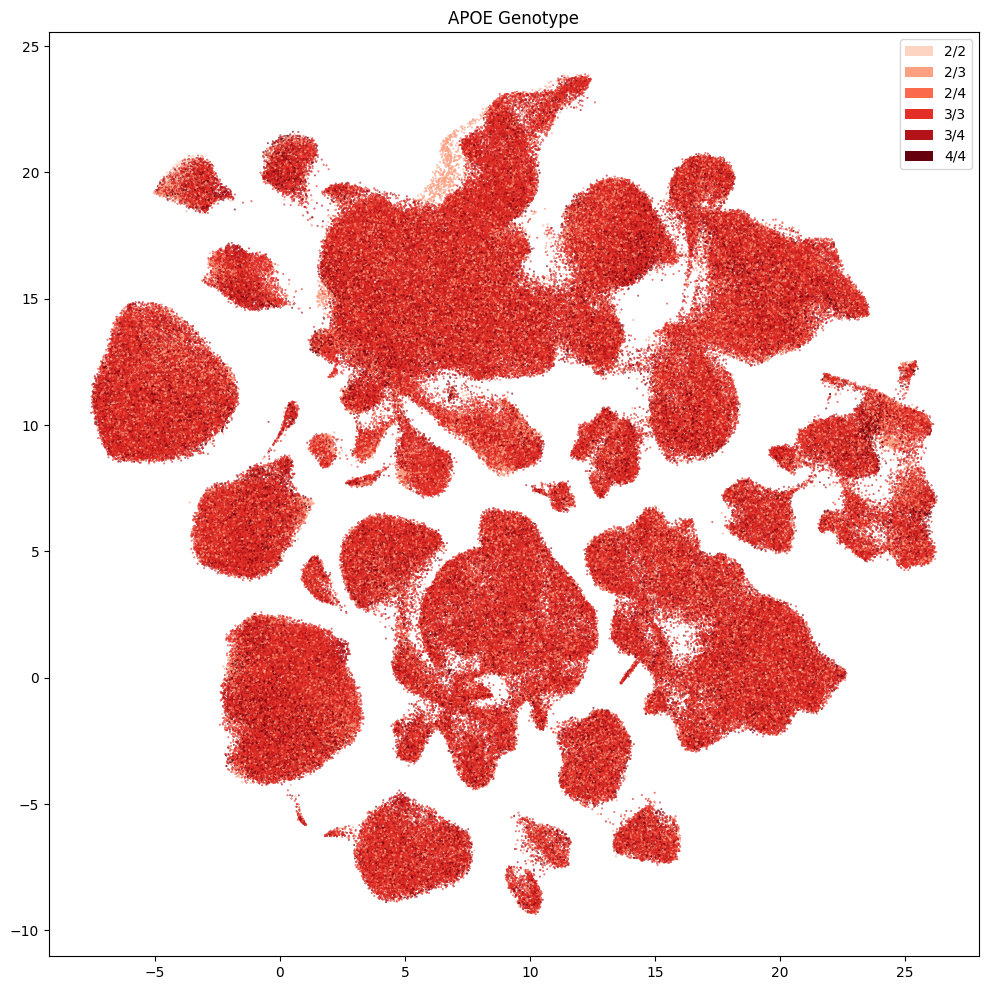

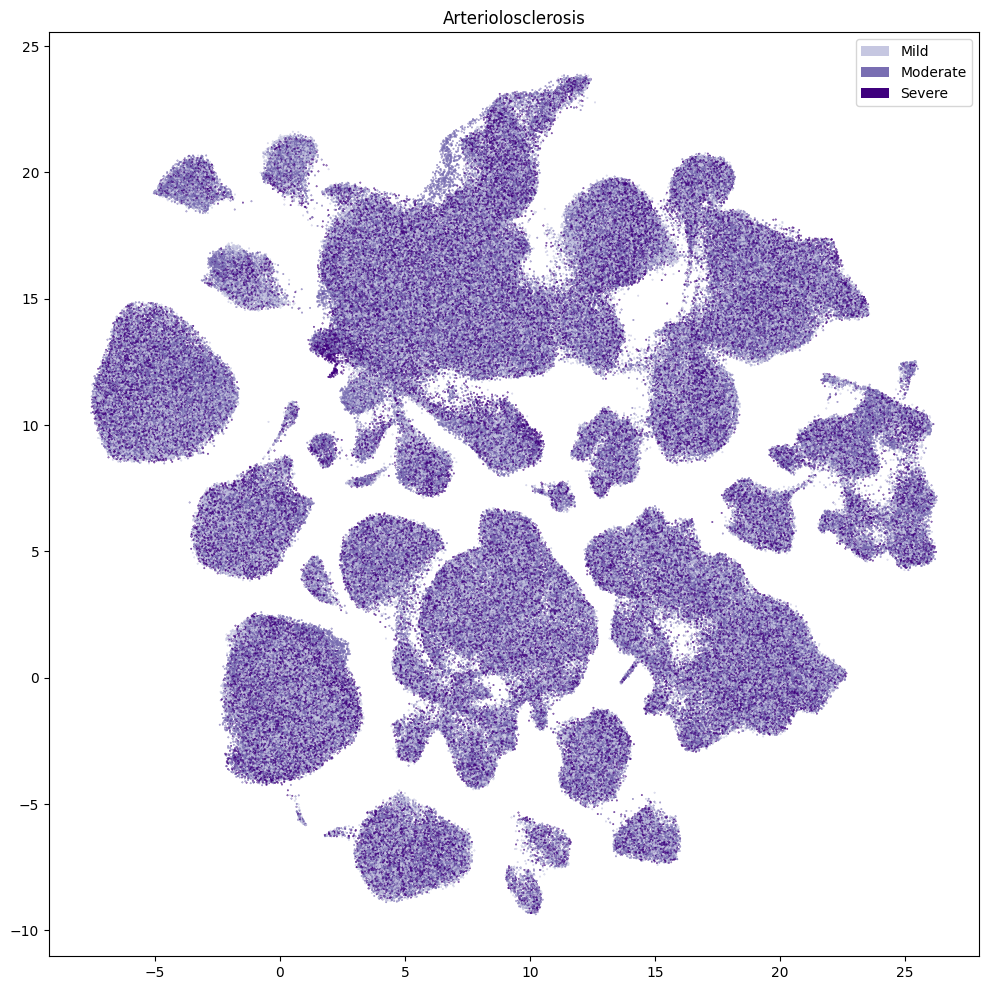

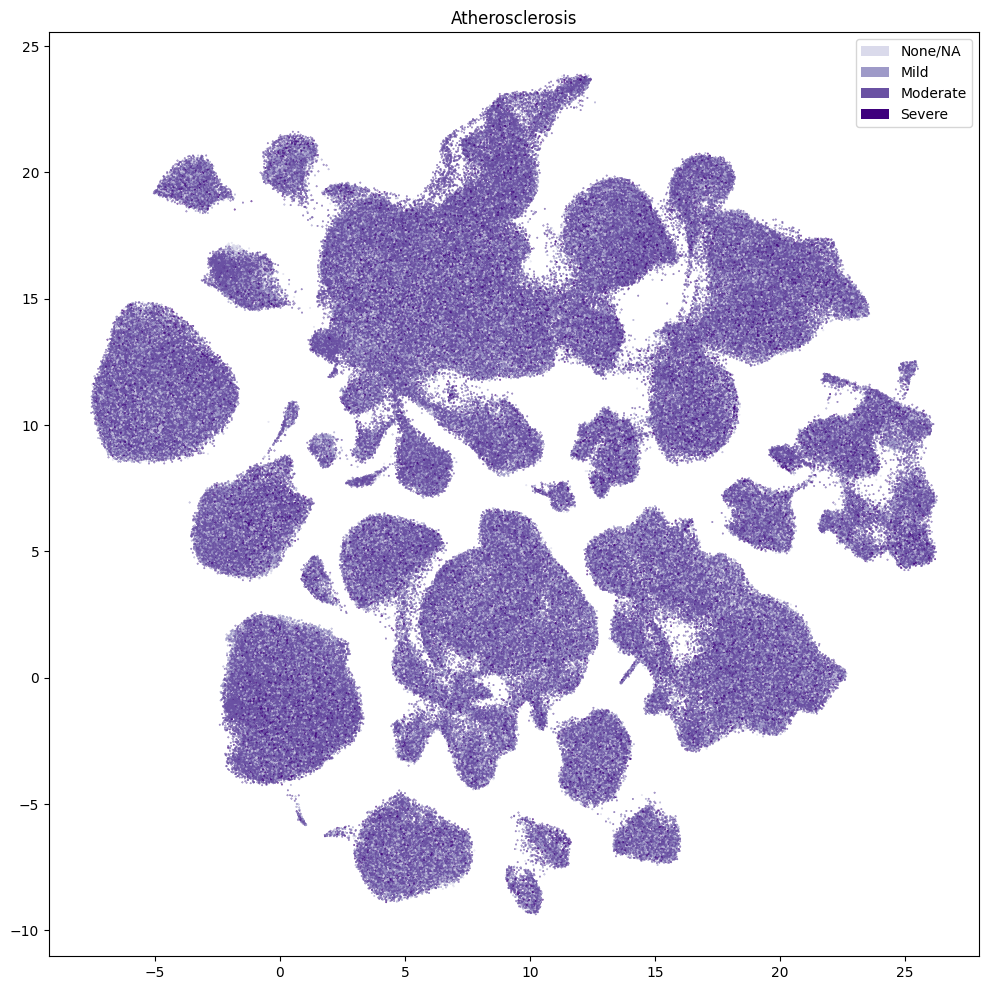

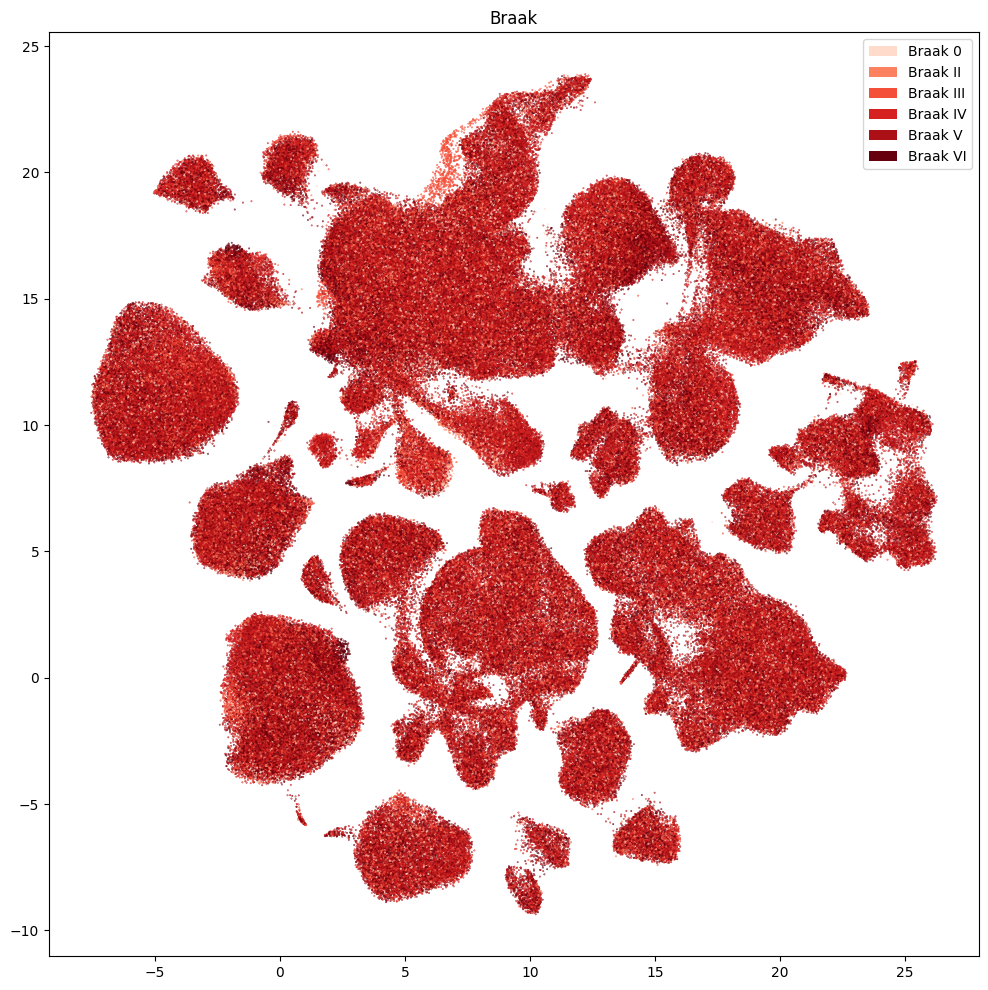

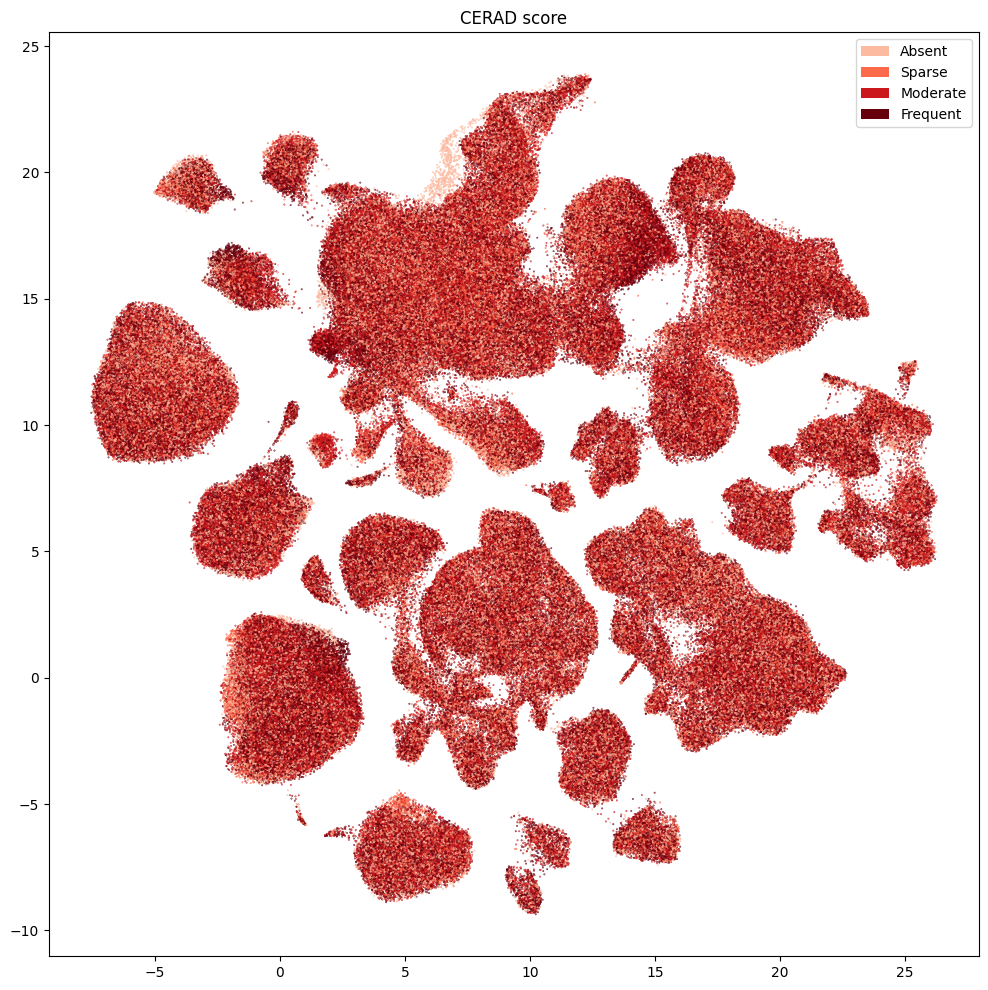

...

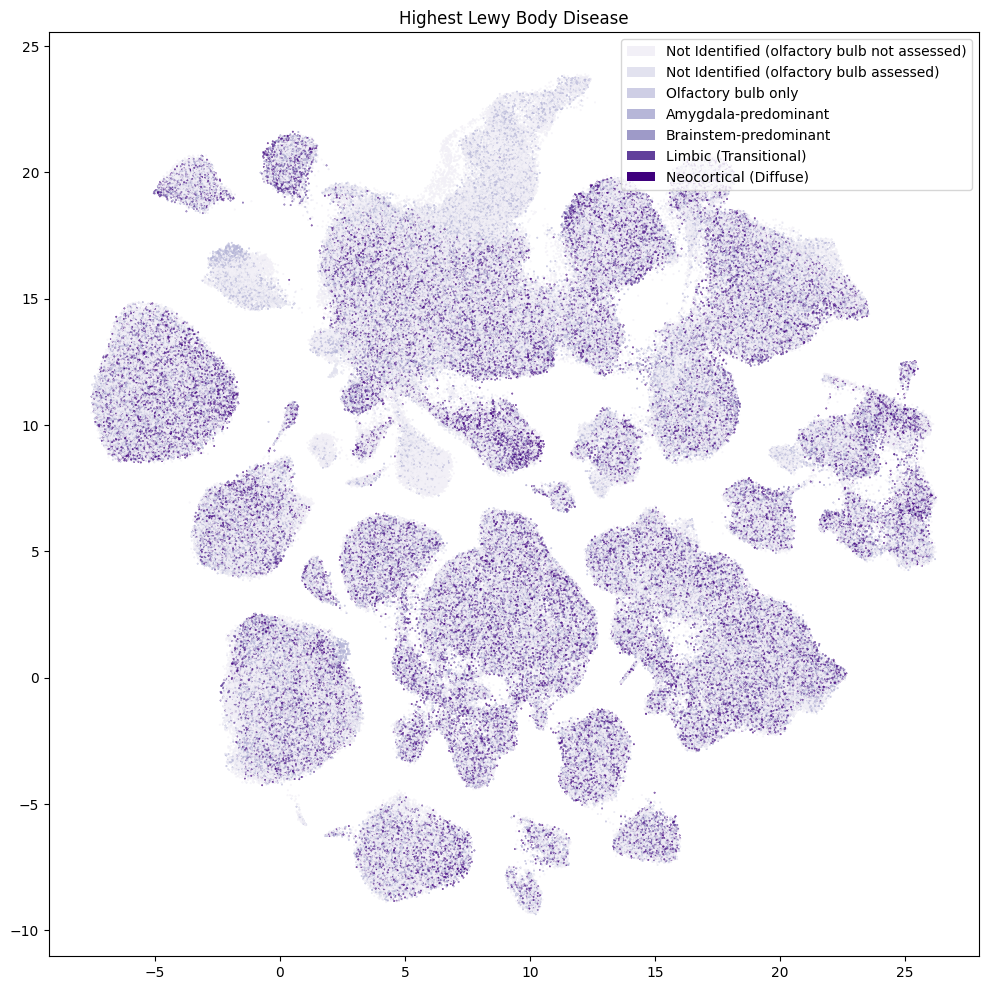

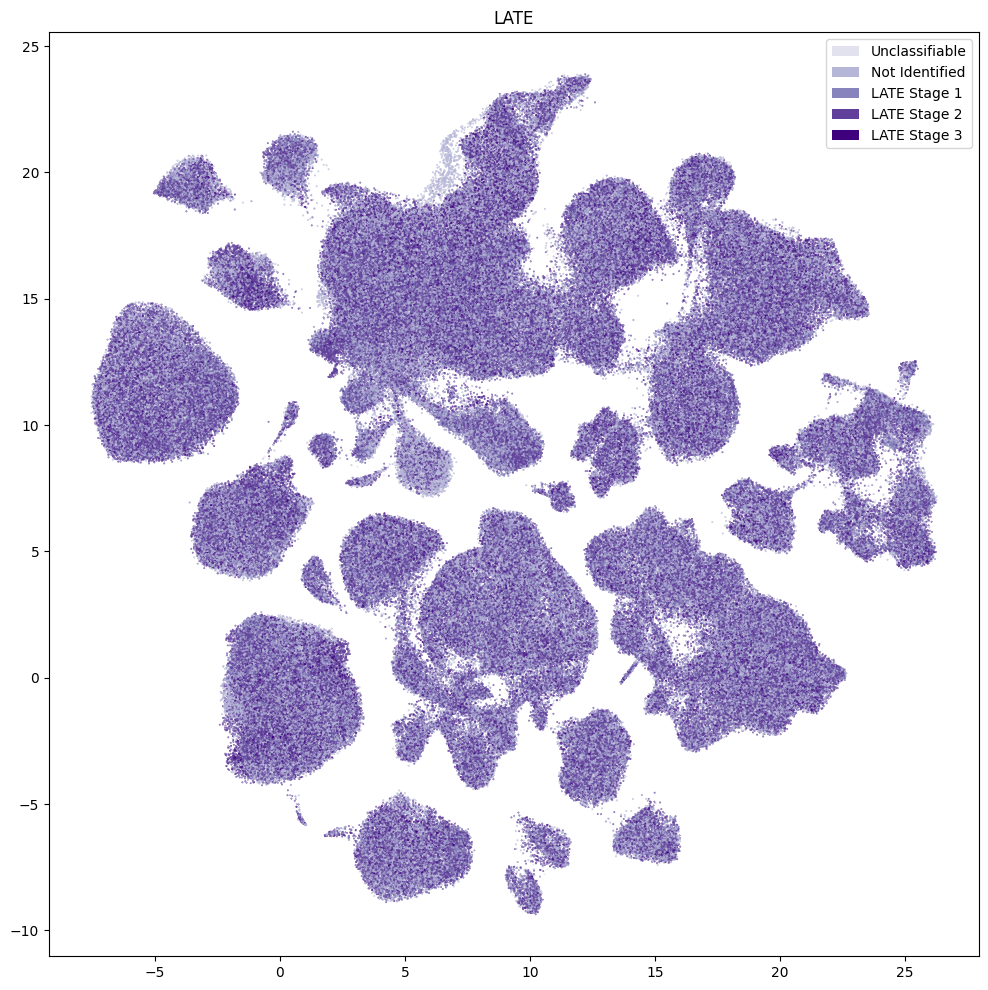

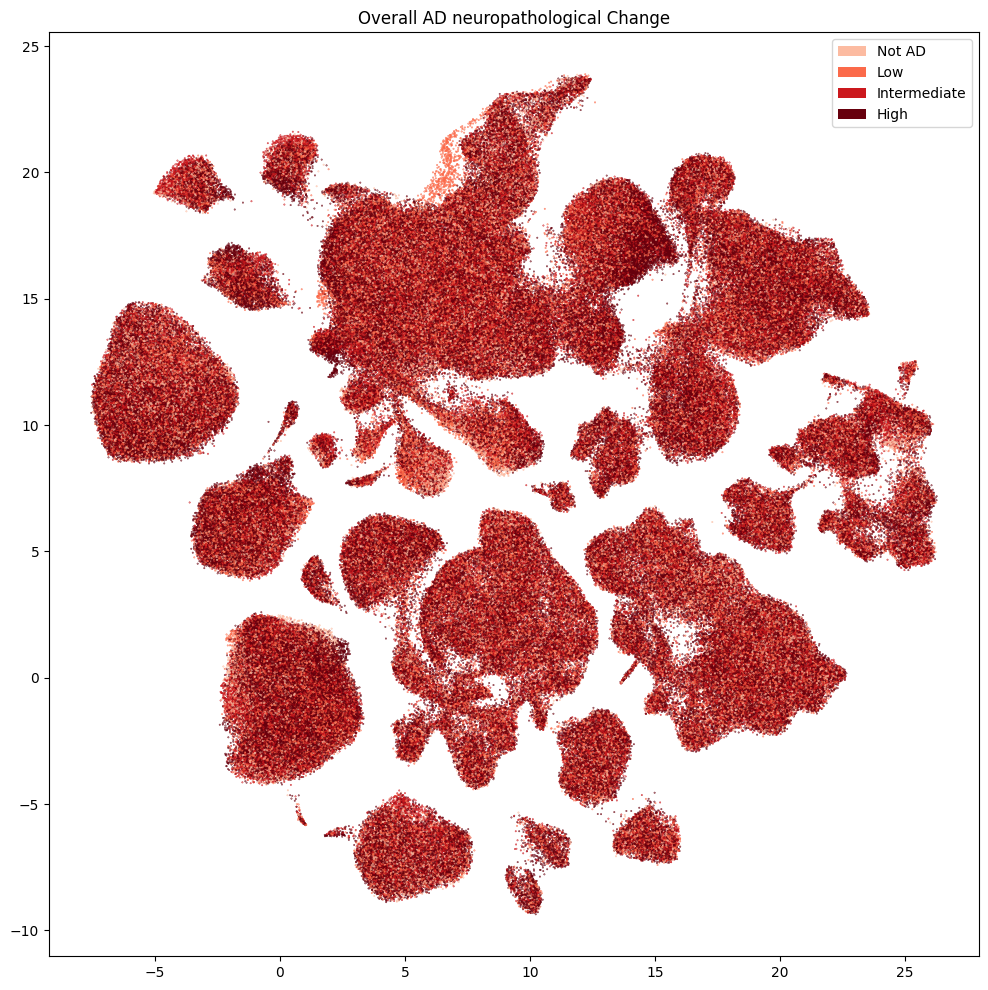

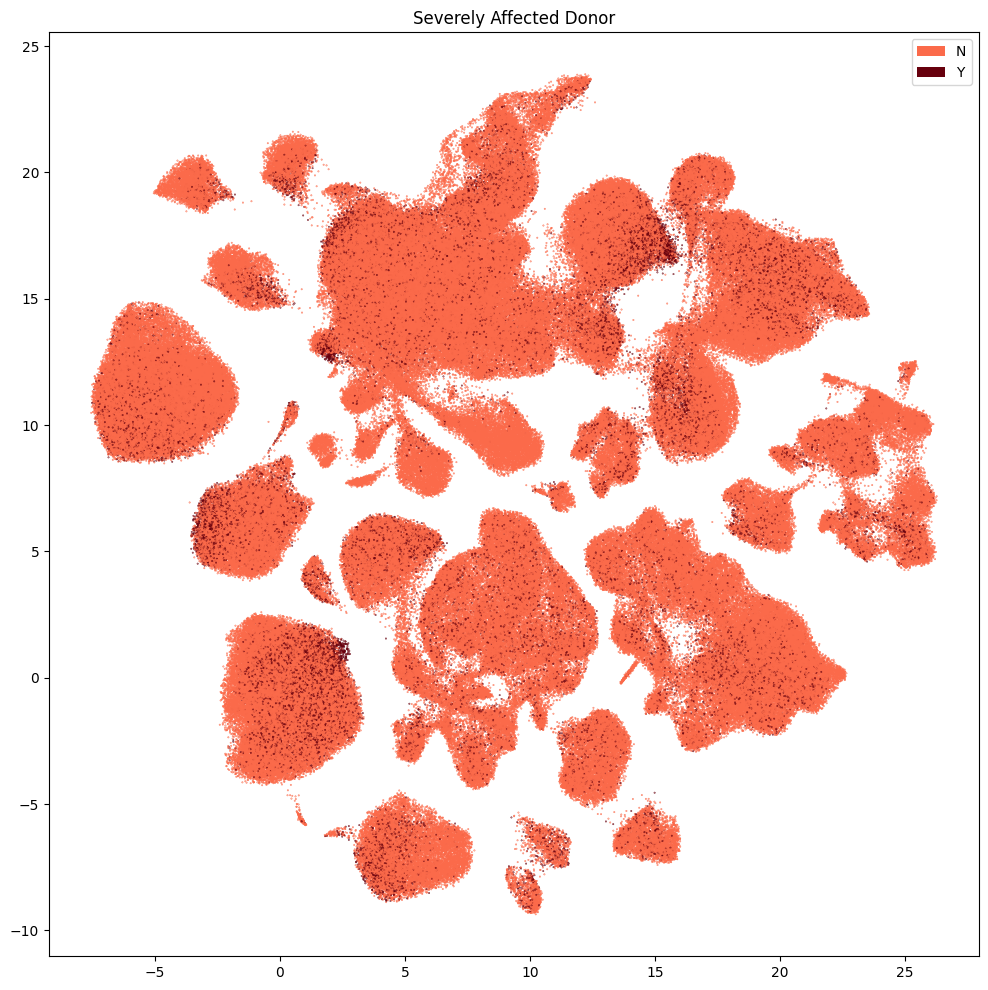

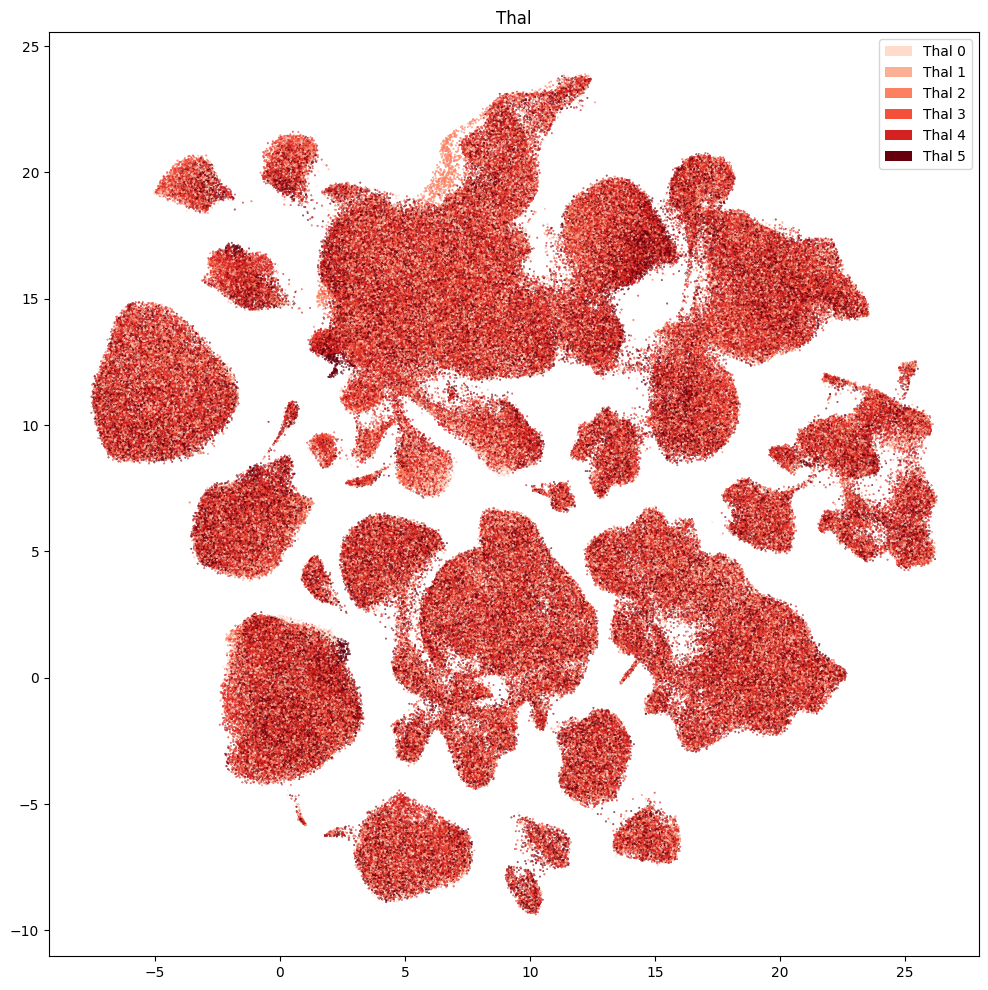

In [26]:
for disease_value in value_sets[value_sets['table'] == 'disease']['field'].unique():
    fig, ax = plot_umap(
        plot_cell_extended['x'],
        plot_cell_extended['y'],
        cc=plot_cell_extended[f'{disease_value}_color'],
        labels=plot_cell_extended[f'{disease_value}'],
        term_orders=plot_cell_extended[f'{disease_value}_order'],
        fig_width=12,
        fig_height=12
    )
    res = ax.set_title(f"{disease_value}")
    plt.show()

Finally, we'll plot the pseudo-progression scores (CPS) for these data.

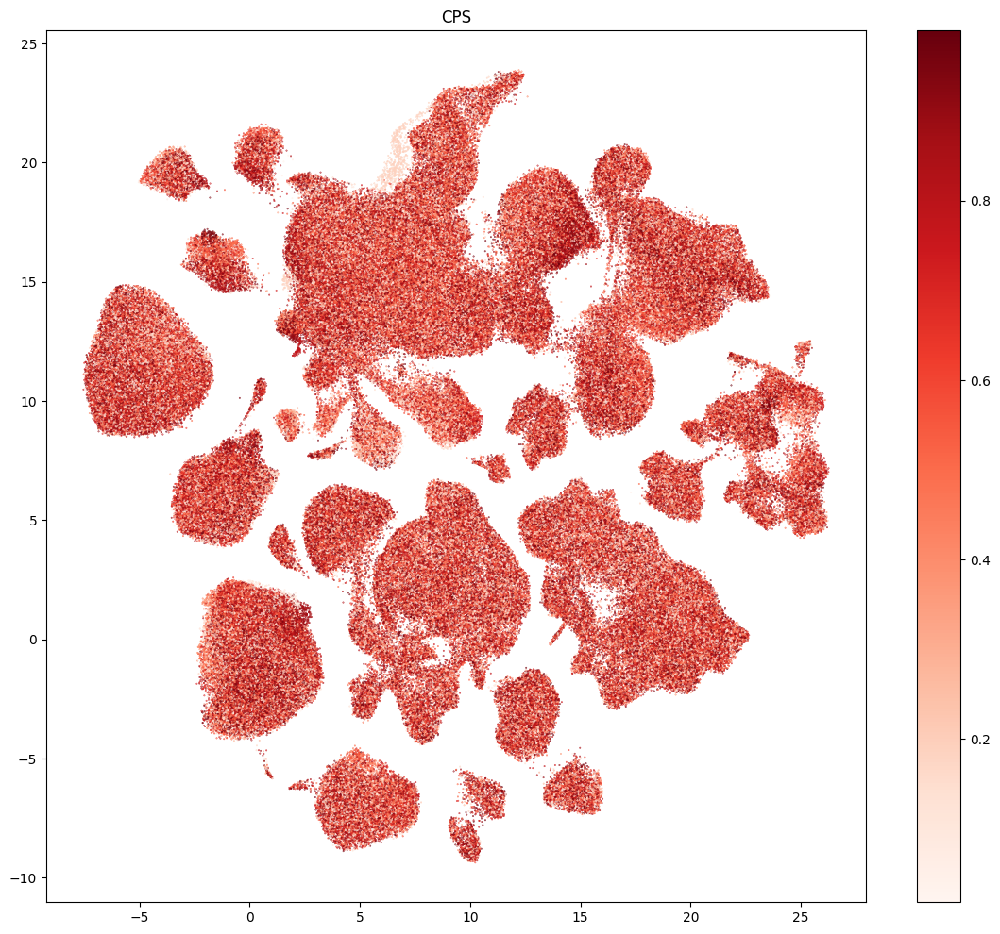

In [27]:
fig, ax = plot_umap(
    plot_cell_extended['x'],
    plot_cell_extended['y'],
    val=plot_cell_extended['CPS_Global'],
    cmap=plt.cm.Reds,
    fig_width=14,
    fig_height=12,
    colorbar=True,
)
res = ax.set_title("CPS")
plt.show()

## Taxonomy Information

The final set of metadata we load into our extended cell metadata file maps the cells into their assigned cluster in the taxonomy. We additionally load metadata for the clusters and compute useful information, such as the number of cells in each taxon at each level of the taxonomy. In this notebook `cluster` refers to the leaf node of the taxonomy as is the case throughout `abc_atlas_access`. In this taxonomy, the highest granularity cell type is called ‘supertype’; therefore, when you see the term ‘cluster’ below it refers to the leaf node of the taxonomy aka, the supertypes.

First, we load information associated with the lowest level in the taxonomy. This includes a useful alias value for each cluster as well as the number of cells in each supertype.

In [28]:
cluster = abc_cache.get_metadata_dataframe(
    directory='SEA-AD-Multiregion-taxonomy',
    file_name='cluster',
    dtype={'number_of_cells': 'Int64'}
).rename(columns={'label': 'cluster_annotation_term_label'}).set_index('cluster_annotation_term_label')
cluster.head()

cluster.csv: 100%|██████████| 6.03k/6.03k [00:00<00:00, 69.5kMB/s]


,cluster_alias,number_of_cells
cluster_annotation_term_label,,
CS20260630_SUPR_001,1,88293
CS20260630_SUPR_002,2,3295
CS20260630_SUPR_003,3,2368
CS20260630_SUPR_004,4,700
CS20260630_SUPR_005,5,14450


Next, we load the table that describes the levels in the taxonomy from class at the highest to supertype at the lowest level.

In [29]:
cluster_annotation_term_set = abc_cache.get_metadata_dataframe(
    directory='SEA-AD-Multiregion-taxonomy',
    file_name='cluster_annotation_term_set'
).rename(columns={'label': 'cluster_annotation_term_label'})
cluster_annotation_term_set

cluster_annotation_term_set.csv: 100%|██████████| 208/208 [00:00<00:00, 1.78kMB/s]


,name,cluster_annotation_term_label,description,order,parent_term_set_label
0,Class,CCN20260630_LEVEL_0,Class,0,NaN
1,Subclass,CCN20260630_LEVEL_1,Subclass,1,CCN20260630_LEVEL_0
2,Supertype,CCN20260630_LEVEL_2,Supertype,2,CCN20260630_LEVEL_1


For the supertypes, we load information on the annotations for each supertype. This also includes the term order and color information which we will use to plot later.

In [30]:
cluster_annotation_term = abc_cache.get_metadata_dataframe(
    directory='SEA-AD-Multiregion-taxonomy',
    file_name='cluster_annotation_term',
).rename(columns={'label': 'cluster_annotation_term_label'}).set_index('cluster_annotation_term_label')
cluster_annotation_term

cluster_annotation_term.csv: 100%|██████████| 32.3k/32.3k [00:00<00:00, 265kMB/s]


,name,cluster_annotation_term_set_label,cluster_annotation_term_set_name,color_hex_triplet,term_order,term_set_order,parent_term_label,parent_term_name,parent_term_set_label,CCN20230508_label
cluster_annotation_term_label,,,,,,,,,,
CS20260630_CLAS_001,Neuronal: GABAergic,CCN20260630_LEVEL_0,Class,#F05A28,1,0,NaN,NaN,NaN,NaN
CS20260630_CLAS_002,Neuronal: Glutamatergic,CCN20260630_LEVEL_0,Class,#00ADF8,2,0,NaN,NaN,NaN,NaN
CS20260630_CLAS_003,Non-neuronal and Non-neural,CCN20260630_LEVEL_0,Class,#808080,3,0,NaN,NaN,NaN,NaN
CS20260630_SCLA_023,Astrocyte,CCN20260630_LEVEL_1,Subclass,#665C47,23,1,CS20260630_CLAS_003,Non-neuronal and Non-neural,CCN20260630_LEVEL_0,NaN
CS20260630_SCLA_021,CA2-4,CCN20260630_LEVEL_1,Subclass,#D5BF41,21,1,CS20260630_CLAS_002,Neuronal: Glutamatergic,CCN20260630_LEVEL_0,NaN
...,...,...,...,...,...,...,...,...,...,...
CS20260630_SUPR_038,Vip_25-SEAAD,CCN20260630_LEVEL_2,Supertype,#492C56,38,2,CS20260630_SCLA_005,Vip,CCN20260630_LEVEL_1,NaN
CS20260630_SUPR_039,Vip_4,CCN20260630_LEVEL_2,Supertype,#D0AEDC,39,2,CS20260630_SCLA_005,Vip,CCN20260630_LEVEL_1,CS20230508_SUPT_0022
CS20260630_SUPR_040,Vip_5,CCN20260630_LEVEL_2,Supertype,#C7A5D3,40,2,CS20260630_SCLA_005,Vip,CCN20260630_LEVEL_1,CS20230508_SUPT_0023


Finally, we load the cluster to cluster annotation membership table. Each row in this table is a mapping between the supertypes and every level of the taxonomy it belongs to, including itself. We'll use this table in a `groupby` to allow us to count up the number of clusters at each taxonomy level and sum the number of cells in each taxon in the taxonomy a all levels.

In [31]:
cluster_to_cluster_annotation_membership = abc_cache.get_metadata_dataframe(
    directory='SEA-AD-Multiregion-taxonomy',
    file_name='cluster_to_cluster_annotation_membership'
).set_index('cluster_annotation_term_label')
membership_with_cluster_info = cluster_to_cluster_annotation_membership.join(
    cluster.reset_index().set_index('cluster_alias')[['number_of_cells']],
    on='cluster_alias'
)
membership_with_cluster_info = membership_with_cluster_info.join(cluster_annotation_term, rsuffix='_anno_term').reset_index()
membership_groupby = membership_with_cluster_info.groupby(
    ['cluster_alias', 'cluster_annotation_term_set_name']
)
membership_with_cluster_info.head()

cluster_to_cluster_annotation_membership.csv: 100%|██████████| 40.6k/40.6k [00:00<00:00, 366kMB/s]


,cluster_annotation_term_label,cluster_annotation_term_set_name,cluster_annotation_term_name,cluster_alias,cluster_annotation_term_set_label,number_of_cells,name,cluster_annotation_term_set_label_anno_term,cluster_annotation_term_set_name_anno_term,color_hex_triplet,term_order,term_set_order,parent_term_label,parent_term_name,parent_term_set_label,CCN20230508_label
0,CS20260630_CLAS_001,Class,Neuronal: GABAergic,1,CCN20260630_LEVEL_0,88293,Neuronal: GABAergic,CCN20260630_LEVEL_0,Class,#F05A28,1,0,NaN,NaN,NaN,NaN
1,CS20260630_CLAS_001,Class,Neuronal: GABAergic,2,CCN20260630_LEVEL_0,3295,Neuronal: GABAergic,CCN20260630_LEVEL_0,Class,#F05A28,1,0,NaN,NaN,NaN,NaN
2,CS20260630_CLAS_001,Class,Neuronal: GABAergic,3,CCN20260630_LEVEL_0,2368,Neuronal: GABAergic,CCN20260630_LEVEL_0,Class,#F05A28,1,0,NaN,NaN,NaN,NaN
3,CS20260630_CLAS_001,Class,Neuronal: GABAergic,4,CCN20260630_LEVEL_0,700,Neuronal: GABAergic,CCN20260630_LEVEL_0,Class,#F05A28,1,0,NaN,NaN,NaN,NaN
4,CS20260630_CLAS_001,Class,Neuronal: GABAergic,5,CCN20260630_LEVEL_0,14450,Neuronal: GABAergic,CCN20260630_LEVEL_0,Class,#F05A28,1,0,NaN,NaN,NaN,NaN


From the membership table, we create three tables via a `groupby`. First the name of each cluster and its parents.

In [32]:
# term_sets = abc_cache.get_metadata_dataframe(directory='WHB-taxonomy', file_name='cluster_annotation_term_set').set_index('label')
cluster_details = membership_groupby['cluster_annotation_term_name'].first().unstack()
cluster_details = cluster_details[cluster_annotation_term_set['name']] # order columns
cluster_details.fillna('Other', inplace=True)
cluster_details.head()

cluster_annotation_term_set_name,Class,Subclass,Supertype
cluster_alias,,,
1,Neuronal: GABAergic,Lamp5 Lhx6,Lamp5_Lhx6_1
2,Neuronal: GABAergic,Lamp5 Lhx6,Lamp5_Lhx6_2-SEAAD
3,Neuronal: GABAergic,Lamp5 Lhx6,Lamp5_Lhx6_3-SEAAD
4,Neuronal: GABAergic,Lamp5 Lhx6,Lamp5_Lhx6_4-SEAAD
5,Neuronal: GABAergic,Lamp5,Lamp5_1


Next the plotting order of each of the taxons and their parents.

In [33]:
cluster_order = membership_groupby['term_order'].first().unstack()
cluster_order.head()

cluster_annotation_term_set_name,Class,Subclass,Supertype
cluster_alias,,,
1,1,1,1
2,1,1,2
3,1,1,3
4,1,1,4
5,1,2,5


Finally, the colors we will use to plot for each of the unique taxons at all levels.

In [34]:
cluster_colors = membership_groupby['color_hex_triplet'].first().unstack()
cluster_colors = cluster_colors[cluster_annotation_term_set['name']]
cluster_colors.head()

cluster_annotation_term_set_name,Class,Subclass,Supertype
cluster_alias,,,
1,#F05A28,#935F50,#C6A299
2,#F05A28,#935F50,#A68880
3,#F05A28,#935F50,#866E67
4,#F05A28,#935F50,#67544F
5,#F05A28,#DA808C,#F9B7C3


Next, we bring it all together by loading the mapping of cells to supertype and join into our final metadata table.

In [35]:
cell_to_cluster_membership = abc_cache.get_metadata_dataframe(
    directory='SEA-AD-Multiregion-taxonomy',
    file_name='cell_to_cluster_membership',
).set_index('cell_label')
cell_to_cluster_membership.head()

cell_to_cluster_membership.csv: 100%|██████████| 295M/295M [00:28<00:00, 10.4MMB/s]    


,cluster_alias,label
cell_label,,
AAACAGCCACTGGCTG-2001_A08,84,CS20260630_SUPR_084
AAACAGCCAGGTTATT-2001_A08,180,CS20260630_SUPR_180
AAACAGCCATTCCTCG-2001_A08,113,CS20260630_SUPR_113
AAACATGCAATGCCTA-2001_A08,80,CS20260630_SUPR_080
AAACATGCACCTCACC-2001_A08,76,CS20260630_SUPR_076


We merge this table with information from our taxons. Again, we'll subset the full set of cells for ease of plotting.

In [36]:
cell_extended = cell_extended.join(cell_to_cluster_membership, rsuffix='_cell_to_cluster_membership', how='inner')
cell_extended = cell_extended.join(cluster_details, on='cluster_alias')
cell_extended = cell_extended.join(cluster_colors, on='cluster_alias', rsuffix='_color')
cell_extended = cell_extended.join(cluster_order, on='cluster_alias', rsuffix='_order')
plot_cell_extended = cell_extended[::10]

del cell_to_cluster_membership

cell_extended.head()

,cell_barcode,barcoded_cell_sample_label,library_label,alignment_job_id,doublet_score,umi_count,donor_label,exp_component_name,feature_matrix_label,dataset_label,...,label,Class,Subclass,Supertype,Class_color,Subclass_color,Supertype_color,Class_order,Subclass_order,Supertype_order
cell_label,,,,,,,,,,,,,,,,,,,,,
TCGCGAGGTATTGGAT-1380_B02,TCGCGAGGTATTGGAT,1380_B02,L8XR_220818_02_H09,1202603549,0.032609,1045.0,H21.33.003,TCGCGAGGTATTGGAT-L8XR_220818_02_H09-1202603549,HIP-10X,SEA-AD-Multiregion-10X,...,CS20260630_SUPR_175,Non-neuronal and Non-neural,Astrocyte,Astro_1,#808080,#665C47,#D1C9BA,3,23,175
CTAAGTGTCATTCGTT-744_E01,CTAAGTGTCATTCGTT,744_E01,L8TX_210729_01_D12,1153814314,0.087912,54610.0,H21.33.042,CTAAGTGTCATTCGTT-L8TX_210729_01_D12-1153814314,MTG-10X,SEA-AD-Multiregion-10X,...,CS20260630_SUPR_084,Neuronal: Glutamatergic,L2/3 IT,L2/3 IT_1,#00ADF8,#B1EC30,#EEF987,2,10,84
GTCACTCCATACCAGT-851_A04,GTCACTCCATACCAGT,851_A04,L8TX_210930_01_E02,1134006384,0.110000,14848.0,H21.33.014,GTCACTCCATACCAGT-L8TX_210930_01_E02-1134006384,DFC-10X,SEA-AD-Multiregion-10X,...,CS20260630_SUPR_085,Neuronal: Glutamatergic,L2/3 IT,L2/3 IT_10,#00ADF8,#B1EC30,#81934A,2,10,85
AACAACCGTATGGTTC-1175_C06,AACAACCGTATGGTTC,1175_C06,L8TX_220331_01_B06,1169929016,0.040000,23598.0,H20.33.016,AACAACCGTATGGTTC-L8TX_220331_01_B06-1169929016,MEC-10X,SEA-AD-Multiregion-10X,...,CS20260630_SUPR_039,Neuronal: GABAergic,Vip,Vip_4,#F05A28,#A45FBF,#D0AEDC,1,5,39
TTTCCTGAGGAGCAAC-1936_A05,TTTCCTGAGGAGCAAC,1936_A05,L8XR_231102_01_F06,1313371088,0.020000,1292.0,H20.33.046,TTTCCTGAGGAGCAAC-L8XR_231102_01_F06-1313371088,AnG-10X,SEA-AD-Multiregion-10X,...,CS20260630_SUPR_096,Neuronal: Glutamatergic,L4 IT,L4 IT_2,#00ADF8,#00E5E5,#B6E3F3,2,11,96


In [37]:
print_column_info(cell_extended)

Number of unique cell_barcode = 3264931 
Number of unique barcoded_cell_sample_label = 907 
Number of unique library_label = 907 
Number of unique alignment_job_id = 912 
Number of unique doublet_score = 2395 
Number of unique umi_count = 164013 
Number of unique donor_label = 84 
Number of unique exp_component_name = 6013346 
Number of unique feature_matrix_label = 10 ['AnG-10X', 'DFC-10X', 'FI-10X', 'HIP-10X', 'ITG-10X', 'LEC-10X', 'MEC-10X', 'MTG-10X', 'STG-10X', 'V1C-10X']
Number of unique dataset_label = 1 ['SEA-AD-Multiregion-10X']
Number of unique donor_species = 1 ['NCBITaxon:9606']
Number of unique species_scientific_name = 1 ['Homo sapiens']
Number of unique species_genus = 1 ['Human']
Number of unique donor_sex = 2 ['Female', 'Male']
Number of unique donor_gender = 2 ['Female', 'Male']
Number of unique donor_age = 29 ['100+ yrs', '65 yrs', '68 yrs', '69 yrs', '70 yrs', '72 yrs', '75 yrs', '77 yrs', '78 yrs', '80 yrs', '81 yrs', '82 yrs', '83 yrs', '84 yrs', '85 yrs', '86 yrs

#### Plotting the taxonomy

Now that we have our cells with associated taxonomy information, we'll plot them into the UMAP we showed previously.

Below we plot the taxonomy mapping of the cells for each level in the taxonomy.

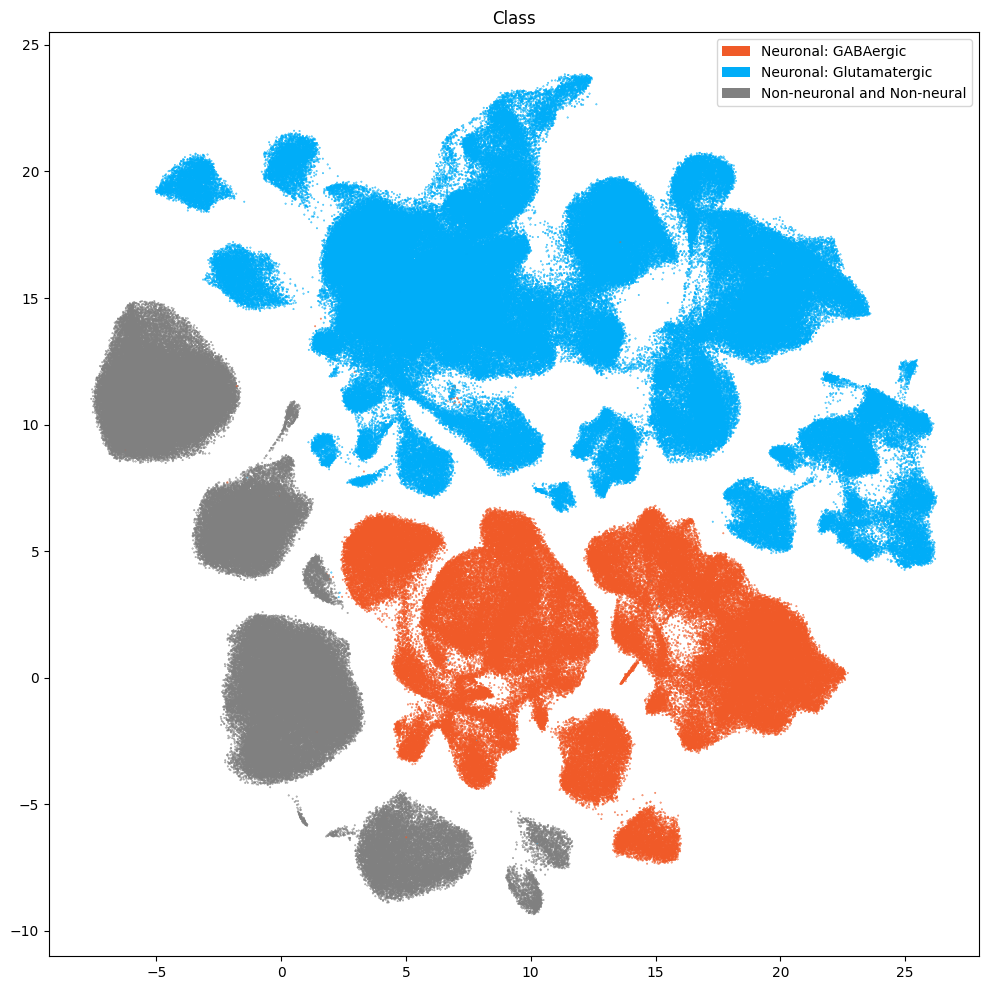

In [38]:
fig, ax = plot_umap(
    plot_cell_extended['x'],
    plot_cell_extended['y'],
    cc=plot_cell_extended['Class_color'],
    labels=plot_cell_extended['Class'],
    term_orders=plot_cell_extended['Class_order'],
    fig_width=12,
    fig_height=12
)
res = ax.set_title("Class")
plt.show()

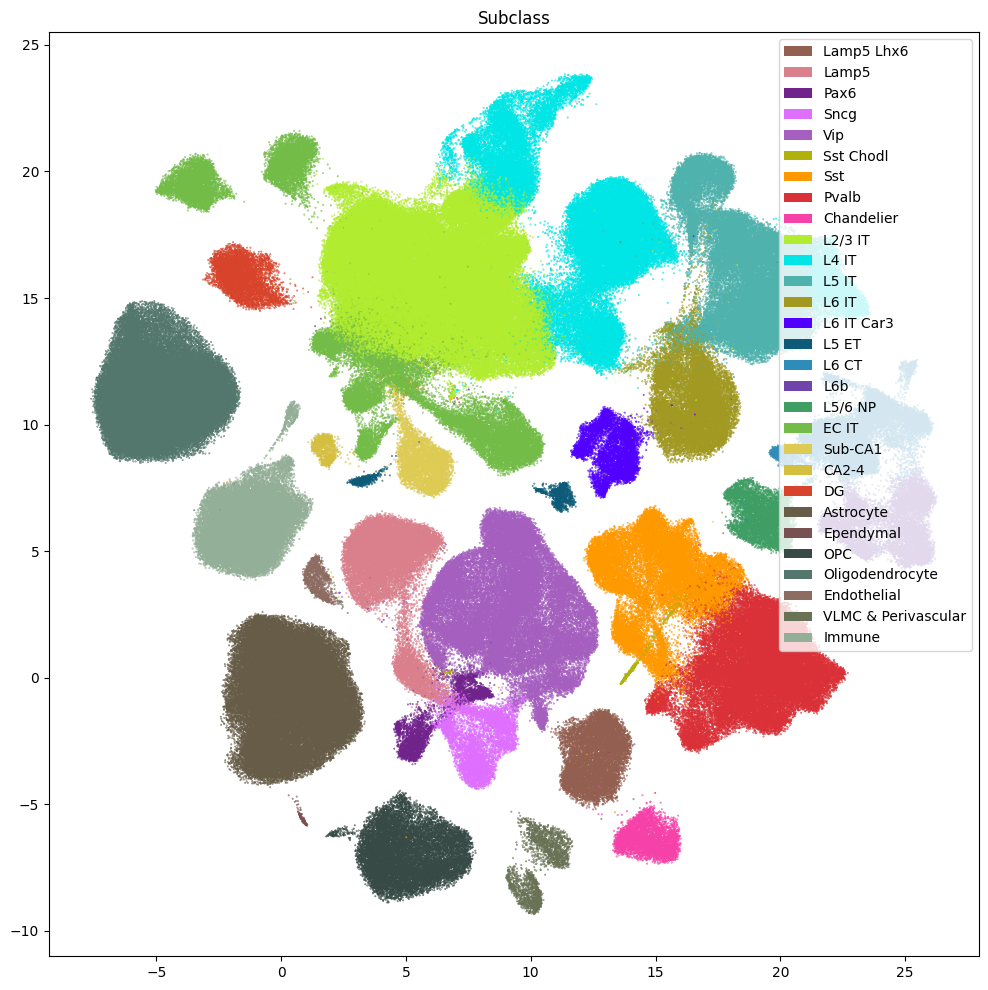

In [39]:
fig, ax = plot_umap(
    plot_cell_extended['x'],
    plot_cell_extended['y'],
    cc=plot_cell_extended['Subclass_color'],
    labels=plot_cell_extended['Subclass'],
    term_orders=plot_cell_extended['Subclass_order'],
    fig_width=12,
    fig_height=12
)
res = ax.set_title("Subclass")
plt.show()

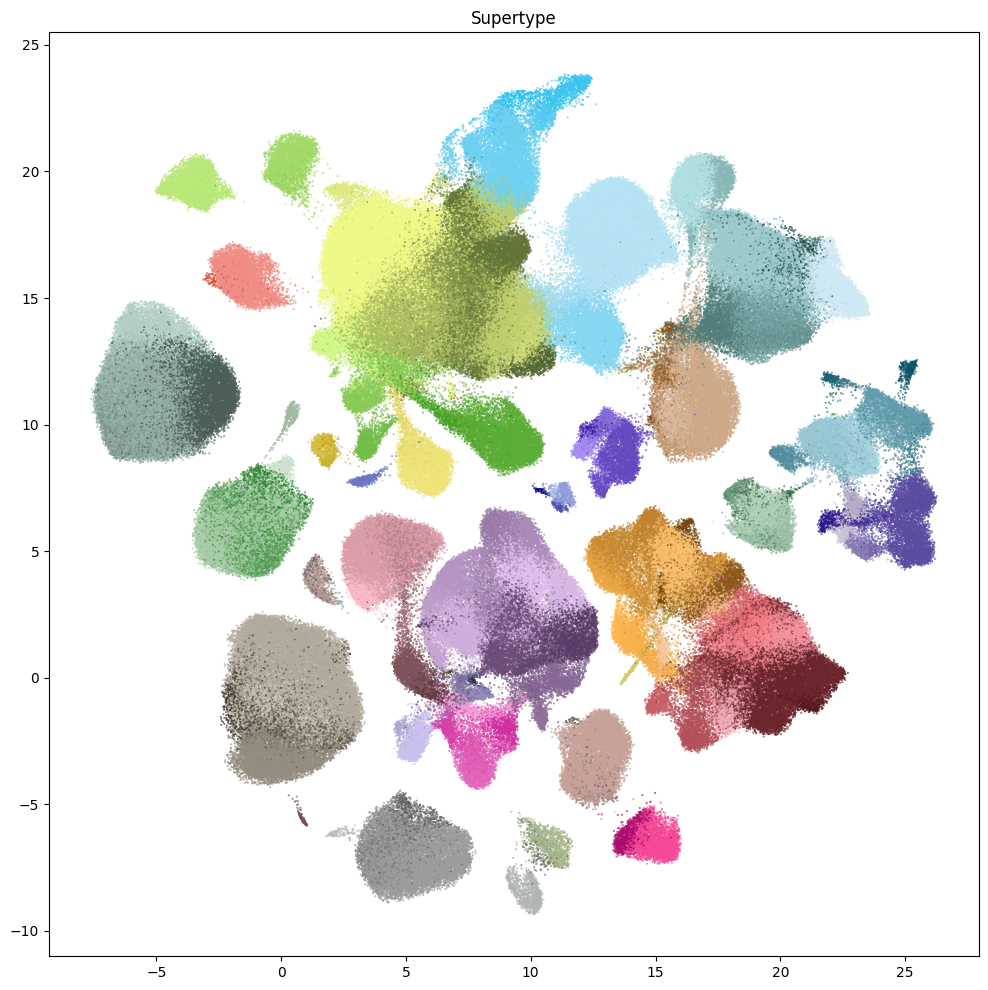

In [40]:
fig, ax = plot_umap(
    plot_cell_extended['x'],
    plot_cell_extended['y'],
    cc=plot_cell_extended['Supertype_color'],
    fig_width=12,
    fig_height=12
)
res = ax.set_title("Supertype")
plt.show()

Below we plot the Subclass level of the taxonomy against paired with a plot Brain Regions in the UMAP.

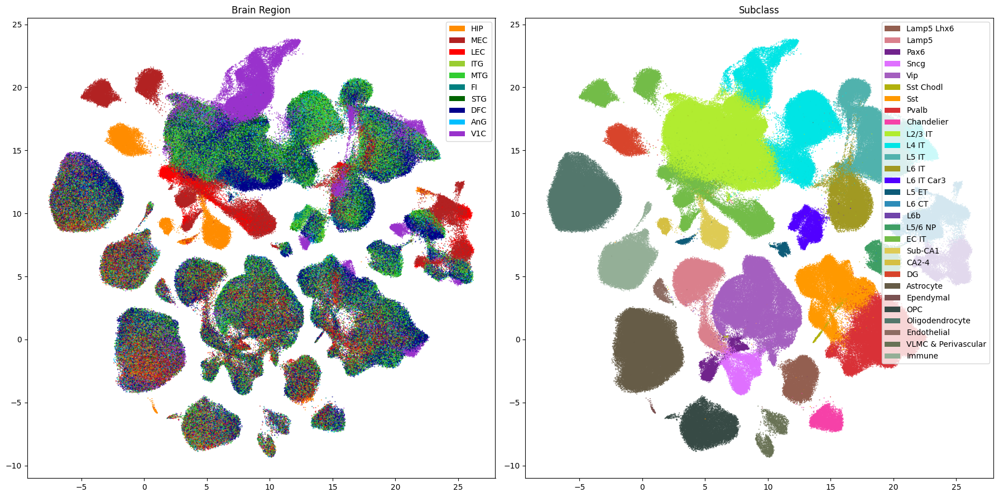

In [41]:
fig, ax = plt.subplots(1, 2)
fig.set_size_inches(18, 9)
ax = ax.flatten()
term_to_plot_1 = 'region_of_interest_label'
plot_umap(
    cell_extended['x'][::10],
    cell_extended['y'][::10],
    cc=cell_extended[term_to_plot_1 + '_color'][::10],
    labels=cell_extended[term_to_plot_1][::10],
    term_orders=cell_extended[term_to_plot_1 + '_order'][::10],
    fig=fig,
    ax=ax[0],
)
ax[0].set_title('Brain Region')
term_to_plot_2 = 'Subclass'
plot_umap(
    cell_extended['x'][::10],
    cell_extended['y'][::10],
    cc=cell_extended[term_to_plot_2 + '_color'][::10],
    labels=cell_extended[term_to_plot_2][::10],
    term_orders=cell_extended[term_to_plot_2 + '_order'][::10],
    fig=fig,
    ax=ax[1],
)
ax[1].set_title(f'Subclass')
plt.tight_layout()
plt.show()

### Aggregating supertype and cells counts.

Let's investigate the taxonomy information a bit more. In this section, we'll create bar plots showing the number of supertypes and cells at each level in the taxonomy.

First, we need to compute the number of supertype that are in each of the cell type taxons above it. This is accomplished by a simple groupby in Pandas.

In [42]:
term_cluster_count = membership_with_cluster_info.reset_index().groupby(
        ['cluster_annotation_term_label']
    )[['cluster_alias']].count()
term_cluster_count.columns = ['number_of_supertypes']
term_cluster_count.head()

,number_of_supertypes
cluster_annotation_term_label,
CS20260630_CLAS_001,83
CS20260630_CLAS_002,91
CS20260630_CLAS_003,33
CS20260630_SCLA_001,4
CS20260630_SCLA_002,6


In [43]:
term_cell_count = membership_with_cluster_info.reset_index().groupby(
    ['cluster_annotation_term_label']
)[['number_of_cells']].sum()
term_cell_count.head()

,number_of_cells
cluster_annotation_term_label,
CS20260630_CLAS_001,1421338
CS20260630_CLAS_002,3110538
CS20260630_CLAS_003,1481470
CS20260630_SCLA_001,94656
CS20260630_SCLA_002,175755


In [44]:
# Join counts with the term dataframe
term_with_counts = cluster_annotation_term.join(term_cluster_count)
term_with_counts = term_with_counts.join(term_cell_count)
term_with_counts.head()

,name,cluster_annotation_term_set_label,cluster_annotation_term_set_name,color_hex_triplet,term_order,term_set_order,parent_term_label,parent_term_name,parent_term_set_label,CCN20230508_label,number_of_supertypes,number_of_cells
cluster_annotation_term_label,,,,,,,,,,,,
CS20260630_CLAS_001,Neuronal: GABAergic,CCN20260630_LEVEL_0,Class,#F05A28,1,0,NaN,NaN,NaN,NaN,83,1421338
CS20260630_CLAS_002,Neuronal: Glutamatergic,CCN20260630_LEVEL_0,Class,#00ADF8,2,0,NaN,NaN,NaN,NaN,91,3110538
CS20260630_CLAS_003,Non-neuronal and Non-neural,CCN20260630_LEVEL_0,Class,#808080,3,0,NaN,NaN,NaN,NaN,33,1481470
CS20260630_SCLA_023,Astrocyte,CCN20260630_LEVEL_1,Subclass,#665C47,23,1,CS20260630_CLAS_003,Non-neuronal and Non-neural,CCN20260630_LEVEL_0,NaN,6,511124
CS20260630_SCLA_021,CA2-4,CCN20260630_LEVEL_1,Subclass,#D5BF41,21,1,CS20260630_CLAS_002,Neuronal: Glutamatergic,CCN20260630_LEVEL_0,NaN,4,10572


Below we create a function to plot the supertype and cell counts in a bar graph, coloring by the associated taxon level.

In [45]:
def bar_plot_by_level_and_type(
        df: pd.DataFrame,
        level: str, fig_width:
        float = 8.5, fig_height:
        float = 4,
        cell_min: int = None,
        supertype_min: int = None
    ):
    """Plot the number of cells by the specified level.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing cluster annotation terms with counts.
    level : str
        The level of the taxonomy to plot (e.g., 'Neighborhood', 'Class', 'Subclass', 'Group', 'Cluster').
    fig_width : float, optional
        Width of the figure in inches. Default is 8.5.
    fig_height : float, optional
        Height of the figure in inches. Default is 4.
    """

    fig, ax = plt.subplots(1, 2)
    fig.set_size_inches(fig_width, fig_height)

    for idx, ctype in enumerate(['supertypes', 'cells']):

        pred = (df['cluster_annotation_term_set_name'] == level)
        sort_order = np.argsort(df[pred]['term_order'])
        names = df[pred]['name'].iloc[sort_order]
        counts = df[pred]['number_of_%s' % ctype].iloc[sort_order]
        colors = df[pred]['color_hex_triplet'].iloc[sort_order]
        
        ax[idx].barh(names, counts, color=colors)
        ax[idx].set_title('Number of %s by %s' % (ctype,level))
        ax[idx].set_xlabel('Number of %s' % ctype)
        if ctype == 'supertypes' and supertype_min is not None:
                ax[idx].set_xlim(left=supertype_min)
        if ctype == 'cells':
            if cell_min is not None:
                ax[idx].set_xlim(left=cell_min)
            ax[idx].set_xscale('log')
        
        if idx > 0:
            ax[idx].set_yticklabels([])

    return fig, ax

Now let's plot the counts the taxonomy levels class and subclass.

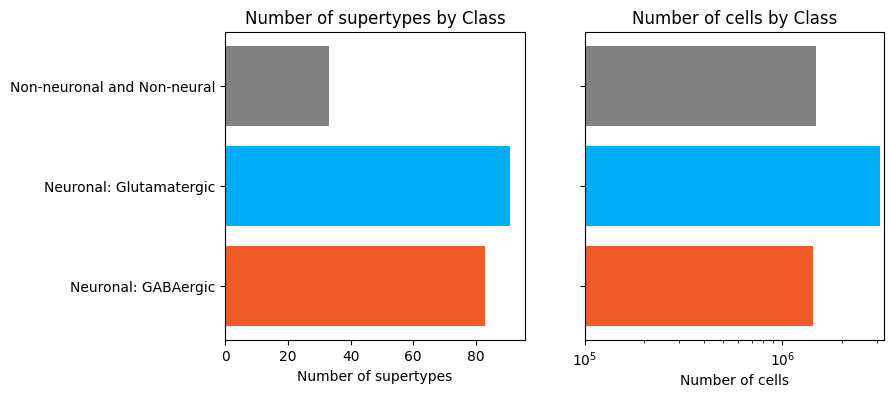

In [46]:
fig, ax = bar_plot_by_level_and_type(term_with_counts, 'Class', cell_min=10 ** 5)
plt.show()

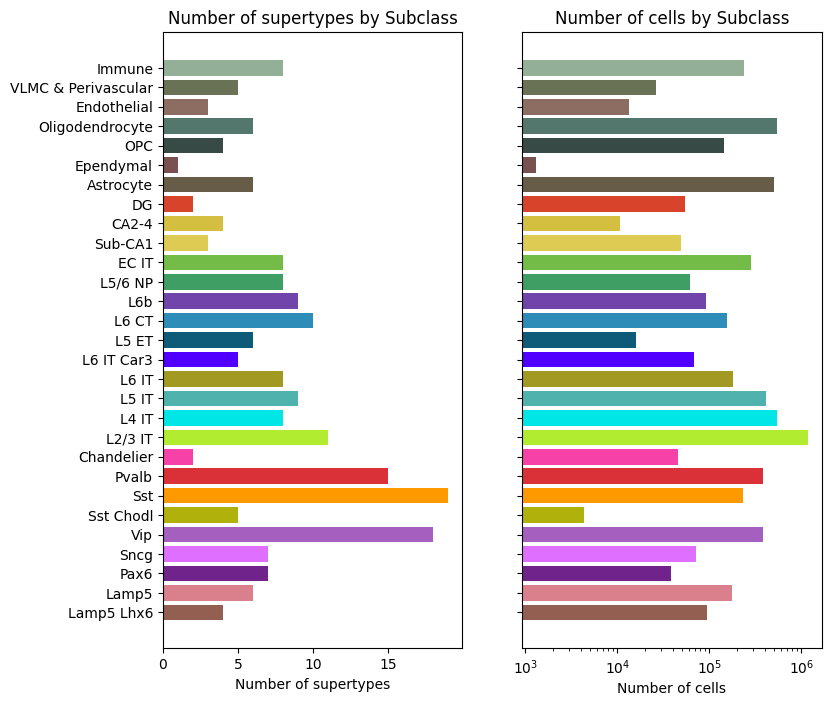

In [47]:
fig, ax = bar_plot_by_level_and_type(
    term_with_counts,
    'Subclass',
    fig_height=8
)
plt.show()

### Visualizing the SEA-AD Multiregion Taxonomy

Term sets: Class, Subclass, and Supertype define the SEA-AD Multiregion taxonomy. We can visualize the taxonomy as a sunburst diagram that shows the single inheritance hierarchy through a series of rings, that are sliced for each annotation term. Each ring corresponds to a level in the hierarchy. We have ordered the rings so that the class level. Rings are divided based on their hierarchical relationship to the parent slice.

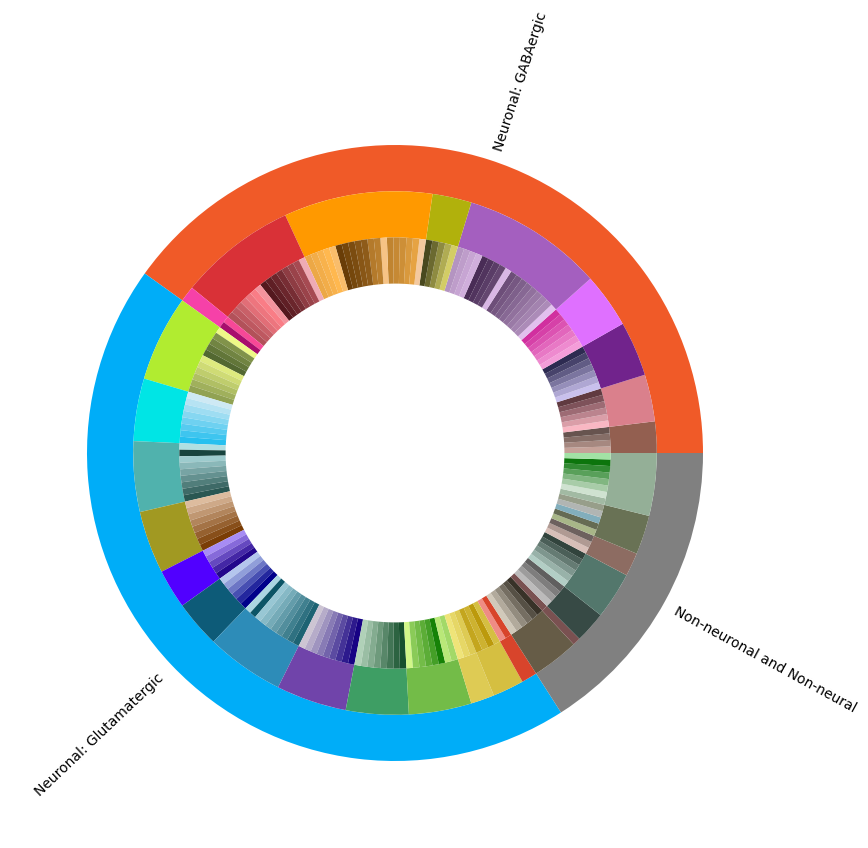

In [49]:
levels = ['Class', 'Subclass', 'Supertype']
df = {}

# Copy the term order of the parent into each of the level below it.
if term_with_counts.index.name != 'cluster_annotation_term_label':
    term_with_counts = term_with_counts.set_index('cluster_annotation_term_label')
term_with_counts['parent_order'] = pd.NA
for idx, row in term_with_counts.iterrows():
    if pd.isna(row['parent_term_label']):
        continue
    term_with_counts.loc[idx, 'parent_order'] = term_with_counts.loc[row['parent_term_label']]['term_order']

term_with_counts = term_with_counts.reset_index()
for lvl in levels:
    pred = term_with_counts['cluster_annotation_term_set_name'] == lvl
    df[lvl] = term_with_counts[pred]
    df[lvl] = df[lvl].sort_values(['parent_order', 'term_order'])

fig, ax = plt.subplots()
fig.set_size_inches(10, 10)
size = 0.15

for i, lvl in enumerate(levels):
    
    if lvl == 'Class':
        ax.pie(df[lvl]['number_of_supertypes'],
               colors=df[lvl]['color_hex_triplet'],
               labels = df[lvl]['name'],
               rotatelabels=True,
               labeldistance=1.025,
               radius=1,
               wedgeprops=dict(width=size, edgecolor=None),
               startangle=0)
    else :
        ax.pie(df[lvl]['number_of_supertypes'],
               colors=df[lvl]['color_hex_triplet'],
               radius=1-i*size,
               wedgeprops=dict(width=size, edgecolor=None),
               startangle=0)
term_with_counts = term_with_counts.set_index('cluster_annotation_term_label')
plt.show()

## Alzheimer's Disease metrics

Below we show some example plots for a specific AD metric (in this case Overall AD neuropathological Change).

The function below returns a heatmap of the fraction of cells in a given pair of features (col_1, col_2) normalized by the total in number cells in the second feature given (col_2).

In [50]:
import matplotlib as mpl

def plot_heatmap(
    df: pd.DataFrame,
    col_1: str,
    col_2: str,
    fig_width: float = 8,
    fig_height: float = 4,
    vmax: float = None,
    cmap: plt.cm = plt.cm.magma,
    log=False
):
    """Plot a heatmap of the proportion of cells in each group defined by col_1 and col_2.

    The values in the heatmap represent the proportion of cells in each group normalized by the
    total number of cells in each column group (col_2).

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing cell metadata and gene expression values.
    col_1 : str
        Column name in df to group by for the rows of the heatmap.
    col_2 : str
        Column name in df to group by for the columns of the heatmap.
    fig_width : float, optional
        Width of the figure in inches.
    fig_height : float, optional
        Height of the figure in inches.
    vmax : float, optional
        Maximum value for the color scale. If None, it is set to the maximum value in the data.
    cmap : matplotlib colormap, optional
        Colormap to use for the heatmap.
    log : bool, optional
        If True, the values will be log-transformed before plotting.

    Returns
    -------
    fig : matplotlib.figure.Figure
        The figure object containing the heatmap.
    ax : array of matplotlib.axes.Axes
        The axes objects for each species.
    """

    fig, ax = plt.subplots(1, 1)
    fig.set_size_inches(fig_width, fig_height)

    grouped = df.groupby([col_1, col_2])['cell_barcode'].count().unstack()
    grouped = grouped.div(grouped.sum(axis=0), axis=1)  # Normalize to proportions
    vmin = grouped.min().min()
    vmax = grouped.max().max()
    if log:
        vmin = np.log10(vmin)
        vmax = np.log10(vmax)
    norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    cmap = sm.get_cmap()

    col_1_order = df.groupby(col_1)[[f'{col_1}_order']].first()
    grouped = grouped.loc[
        col_1_order.sort_values(f'{col_1}_order').index
    ]

    col_2_order = df.groupby(col_2)[[f'{col_2}_order']].first()
    grouped = grouped[
        col_2_order.sort_values(f'{col_2}_order').index
    ]

    arr = grouped.to_numpy().astype('float')
    if log:
        arr = np.log10(arr)

    ax.imshow(arr, cmap=cmap, aspect='auto', vmin=vmin, vmax=vmax)
    xlabs = grouped.columns.values
    ylabs = grouped.index.values

    ax.set_yticks(range(len(ylabs)))
    ax.set_yticklabels(ylabs)
    ax.set_xticks(range(len(xlabs)))
    ax.set_xticklabels(xlabs)

    cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.01, pad=0.01)
    cbar.set_label('Proportion of Cells')
    plt.subplots_adjust(wspace=0.00, hspace=0.00)
    
    return fig, ax

Below we plot the fraction of cells in a given Subclass across AD Neuropathological Change. Here we can see how the proportion of cell types changes as the AD Metric advances.

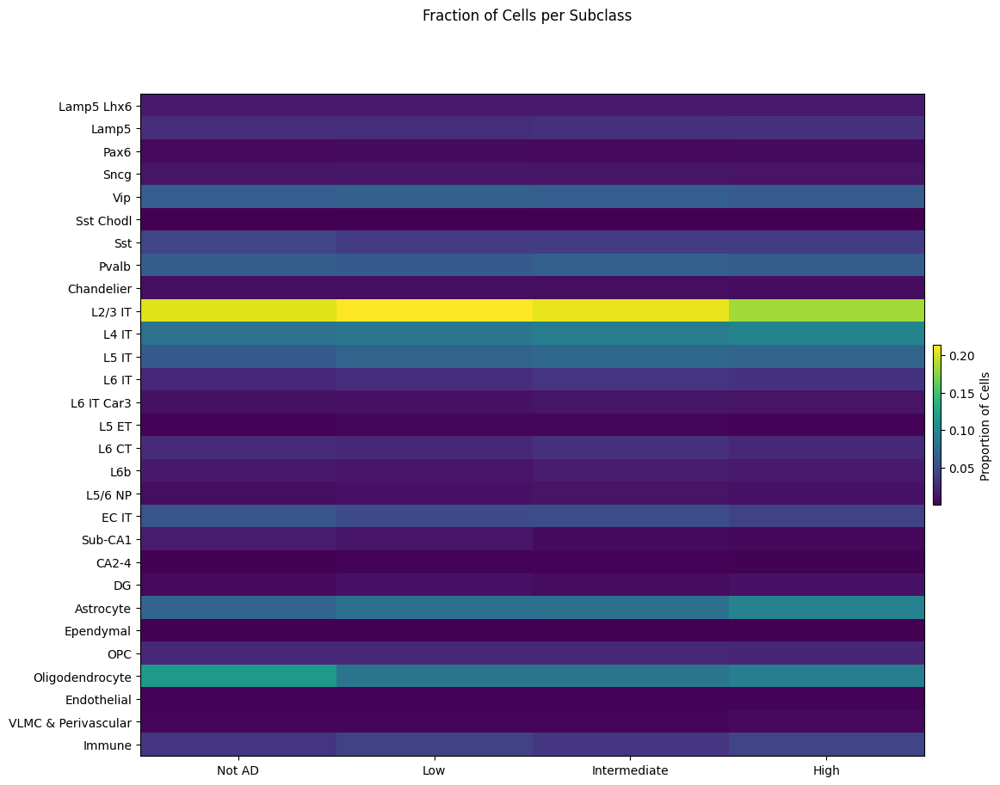

In [51]:
fig, ax = plot_heatmap(
    df=cell_extended,
    col_1="Subclass",
    col_2="Overall AD neuropathological Change",
    fig_width=12,
    fig_height=10,
    cmap=plt.cm.viridis
)
fig.suptitle('Fraction of Cells per Subclass')
plt.show()

In the next tutorial, we show how to access and use [SEA-AD Mutliregion gene expression data](https://alleninstitute.github.io/abc_atlas_access/notebooks/sea-ad_multiregion_10X_RNASeq.html). You can also investigate the SEA-AD Caudate data and taxonomy [here](https://alleninstitute.github.io/abc_atlas_access/notebooks/sea-ad_cah_clustering_analysis_and_annotation.html).